In [ ]:
# Building a separate folder for west Bengal Budget Speeches

In [ ]:
import os
from pathlib import Path

INPUT_DIR = Path("./west_bengal_budgets")

# Ensure the input directory exists
INPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Content of the target input directory ({INPUT_DIR.resolve()}):")
!ls -l {INPUT_DIR.resolve()}

print("\nContent of the main Colab content directory (/content/ - common upload location):")
!ls -l /content/

print("\nIf you mounted Google Drive, check its contents (e.g., /content/drive/MyDrive/):")
!ls -l /content/drive/MyDrive/ 2>/dev/null || echo "Google Drive not mounted or empty."

print("\n\nInstructions:\n1. Locate your uploaded PDF file(s) in the output above (e.g., in `/content/` or `/content/drive/MyDrive/`).\n2. Move them to the `west_bengal_budgets` directory. For example, if your file is named `budget_speech.pdf` and it's in `/content/`, run: `!mv /content/budget_speech.pdf {INPUT_DIR}/`\n3. IMPORTANT: Ensure your PDF filenames include a 4-digit year (e.g., `2023_budget.pdf`). If not, rename them after moving.\n4. Once files are moved and correctly named, re-run the main script (the large code cell at the beginning) again.")

Content of the target input directory (/content/west_bengal_budgets):
total 132500
-rw-r--r-- 1 root root   244849 Sep 27 13:56  2005_English.pdf
-rw-r--r-- 1 root root   237245 Sep 27 13:56  2006_English.pdf
-rw-r--r-- 1 root root   136055 Sep 27 13:56  2007_English.pdf
-rw-r--r-- 1 root root   289405 Sep 27 13:56  2008_English.pdf
-rw-r--r-- 1 root root   101599 Sep 27 13:56  2009_English.pdf
-rw-r--r-- 1 root root   205545 Sep 27 13:56 '2010_English wb.pdf'
-rw-r--r-- 1 root root   212123 Sep 27 13:56 '2011_English budget speech.pdf'
-rw-r--r-- 1 root root   212123 Sep 27 13:56  2011_English.pdf
-rw-r--r-- 1 root root   338442 Sep 27 13:56  2012_English.pdf
-rw-r--r-- 1 root root   203765 Sep 27 13:56  2013_English.pdf
-rw-r--r-- 1 root root   157661 Sep 27 13:56  2014_English.pdf
-rw-r--r-- 1 root root  1614212 Sep 27 13:56  2015_English.pdf
-rw-r--r-- 1 root root   157894 Sep 27 13:56  2016_English.pdf
-rw-r--r-- 1 root root   205949 Sep 27 13:56  2017_English.pdf
-rw-r--r-- 1 roo

In [ ]:
!apt-get -qq update
!apt-get -qq install -y poppler-utils
!pip install -q pandas numpy matplotlib openpyxl

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package poppler-utils.
(Reading database ... 122809 files and directories currently installed.)
Preparing to unpack .../poppler-utils_24.02.0-1ubuntu9.9_amd64.deb ...
Unpacking poppler-utils (24.02.0-1ubuntu9.9) ...
Setting up poppler-utils (24.02.0-1ubuntu9.9) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [ ]:
#Calculating the NLP of west bengal

In [ ]:
from pathlib import Path
import re
import subprocess
import shutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------
BASE_DIR = Path(".")
PDF_DIR = BASE_DIR / "west_bengal_budgets"
OUT_DIR = BASE_DIR / "wb_budget_fast_output"
TEXT_DIR = OUT_DIR / "clean_text"
PLOT_DIR = OUT_DIR / "plots"

PDF_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)
TEXT_DIR.mkdir(exist_ok=True)
PLOT_DIR.mkdir(exist_ok=True)

# Existing research panel locations that may already exist.
PANEL_CANDIDATES = [
    BASE_DIR / "rhetoric_allocation_panel.csv",
    BASE_DIR / "wb_budget_nlp_research" / "rhetoric_allocation_panel.csv",
]

BUDGET_INPUT = BASE_DIR / "budget_allocation_input.csv"

# ------------------------------------------------------------
# 9-SECTOR RESEARCH CROSSWALK
# ------------------------------------------------------------
SECTORS = [
    "agriculture",
    "education",
    "health",
    "industry",
    "employment",
    "welfare",
    "infrastructure",
    "tourism",
    "environment",
]

POLICY_TERMS = {
    "agriculture": [
        "agriculture", "agricultural", "farmer", "farmers", "cultivation",
        "crop", "crops", "irrigation", "fertilizer", "fertilisers",
        "fertilizer", "fertilisers", "agri", "kisan", "agriculturists",
        "tea garden", "tea gardens", "fisheries", "fishery", "livestock",
        "animal husbandry", "horticulture", "foodgrain", "foodgrains",
    ],
    "industry": [
        "industry", "industrial", "industries", "manufacturing",
        "investment", "industrialisation", "industrialization",
        "factory", "factories", "large industry", "large industries",
    ],
    "employment": [
        "employment", "employ", "employed", "unemployment",
        "job", "jobs", "livelihood", "work opportunity",
        "employment opportunity", "employment opportunities",
        "self-employment", "self employment", "worker", "workers",
        "skill development", "vocational training",
    ],
    "education": [
        "education", "educational", "school", "schools", "college",
        "colleges", "university", "universities", "student", "students",
        "higher education", "primary education", "secondary education",
        "literacy", "teacher", "teachers", "madrasa", "madrasah",
    ],
    "health": [
        "health", "healthcare", "hospital", "hospitals", "medical",
        "medicine", "medicines", "doctor", "doctors", "nursing",
        "vaccination", "vaccine", "vaccines", "public health",
        "family welfare", "health centre", "health centres",
        "health center", "health centers",
    ],
    "welfare": [
        "welfare", "social security", "pension", "pensions",
        "social assistance", "beneficiary", "beneficiaries",
        "food security", "old age", "widow", "disability",
        "backward classes", "scheduled caste", "scheduled tribe",
        "minority", "poor", "poverty", "relief", "social protection",
    ],
    "infrastructure": [
        "infrastructure", "road", "roads", "bridge", "bridges",
        "transport", "communication", "housing", "urban development",
        "water supply", "sanitation", "irrigation", "power",
        "electricity", "energy", "construction", "project", "projects",
    ],
    "tourism": [
        "tourism", "tourist", "tourists", "tourist destination",
        "tourist destinations", "heritage", "eco-tourism",
        "ecotourism",
    ],
    "environment": [
        "environment", "environmental", "climate", "climate change",
        "pollution", "forest", "forests", "biodiversity", "green",
        "renewable", "renewable energy", "conservation", "ecology",
        "waste management",
    ],
}

FISCAL_TERMS = {
    "taxation": [
        "tax", "taxes", "taxation", "vat", "gst", "sales tax",
        "profession tax", "excise", "stamp duty", "registration fee",
        "customs duty", "taxpayer", "taxpayers", "tax administration",
        "tax revenue",
    ],
    "revenue": [
        "revenue", "receipts", "revenue receipts", "own revenue",
        "revenue collection", "revenue mobilisation", "revenue mobilization",
    ],
    "expenditure": [
        "expenditure", "spending", "outlay", "allocation",
        "capital expenditure", "revenue expenditure", "development expenditure",
        "plan expenditure", "non-plan expenditure",
    ],
    "deficit_surplus": [
        "deficit", "surplus", "fiscal deficit", "revenue deficit",
        "primary deficit", "fiscal surplus", "budget deficit",
    ],
    "debt_borrowing": [
        "debt", "borrowing", "borrowings", "loan", "loans",
        "interest payment", "interest payments", "public debt",
        "market borrowing",
    ],
    "transfers_devolution": [
        "devolution", "transfers", "central transfer", "central transfers",
        "finance commission", "share of central taxes", "grants",
        "grant", "central assistance",
    ],
}

# ------------------------------------------------------------
# HELPERS
# ------------------------------------------------------------
def extract_text_fast(pdf_path):
    """
    Extract machine-readable text using pdftotext.
    NO OCR.
    """
    pdftotext = shutil.which("pdftotext")
    if pdftotext is None:
        raise RuntimeError(
            "pdftotext was not found. Install Poppler/pdftotext and rerun."
        )

    try:
        result = subprocess.run(
            [pdftotext, "-layout", str(pdf_path), "-"],
            capture_output=True,
            text=True,
            encoding="utf-8",
            errors="ignore",
            timeout=120,
        )
        return result.stdout or ""
    except Exception as e:
        print(f"  Extraction error: {e}")
        return ""


def clean_text(text):
    text = text.replace("\x0c", " ")
    text = re.sub(r"-\s*\n\s*", "", text)       # join hyphenated words
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[^A-Za-z0-9%.,;:()'’&/\-\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip().lower()


def word_count(text):
    return len(re.findall(r"\b[a-zA-Z]+\b", text))


def count_terms(text, terms):
    """
    Count non-overlapping occurrences of each dictionary phrase.
    Longer phrases are counted before shorter phrases.
    """
    total = 0
    for term in sorted(terms, key=len, reverse=True):
        pattern = r"(?<![a-z])" + re.escape(term.lower()) + r"(?![a-z])"
        total += len(re.findall(pattern, text))
    return total


def get_year(path):
    m = re.search(r"(20\d{2})", path.stem)
    return int(m.group(1)) if m else None


def shares_from_counts(row):
    vals = np.array([row[f"{s}_mentions"] for s in SECTORS], dtype=float)
    total = vals.sum()
    if total == 0:
        return np.zeros(len(SECTORS))
    return vals / total


def savefig(name):
    plt.tight_layout()
    plt.savefig(PLOT_DIR / name, dpi=300, bbox_inches="tight")
    plt.close()


def annotate_lines(ax, df, cols, decimals=1, fontsize=7, offset=(0, 5)):
    """
    Put the numerical value beside every point in a line chart.
    """
    for col in cols:
        for x, y in zip(df["year"], df[col]):
            if pd.notna(y):
                ax.annotate(
                    f"{y:.{decimals}f}",
                    (x, y),
                    xytext=offset,
                    textcoords="offset points",
                    ha="center",
                    va="bottom",
                    fontsize=fontsize,
                )


def annotate_heatmap(ax, data, decimals=1, fontsize=6):
    """
    Put the numerical value inside every heatmap cell.
    """
    arr = data.to_numpy(dtype=float)
    for i in range(arr.shape[0]):
        for j in range(arr.shape[1]):
            if np.isfinite(arr[i, j]):
                ax.text(
                    j, i, f"{arr[i, j]:.{decimals}f}",
                    ha="center",
                    va="center",
                    fontsize=fontsize,
                )


# ------------------------------------------------------------
# 1. EXTRACT PDF TEXT — NO OCR
# ------------------------------------------------------------
pdfs = sorted(PDF_DIR.glob("*.pdf"))

if not pdfs:
    raise FileNotFoundError(
        f"No PDF files found in {PDF_DIR.resolve()}. "
        "Put your budget speech PDFs in ./west_bengal_budgets/"
    )

speech_rows = []
quality_rows = []

print("\n=== FAST PDF EXTRACTION ===")

for pdf in pdfs:
    year = get_year(pdf)
    if year is None:
        print(f"Skipping {pdf.name}: no year detected.")
        continue

    txt_file = TEXT_DIR / f"{year}.txt"

    # Reuse extracted text if it already exists.
    if txt_file.exists():
        text = txt_file.read_text(encoding="utf-8", errors="ignore")
        source = "cached_text"
    else:
        print(f"Extracting {pdf.name} ...")
        raw = extract_text_fast(pdf)
        text = clean_text(raw)
        txt_file.write_text(text, encoding="utf-8")
        source = "pdftotext"

    words = word_count(text)

    # Very short output usually means the PDF is scanned.
    status = "OK" if words >= 1000 else "LOW_TEXT_FLAG"

    quality_rows.append({
        "year": year,
        "pdf": pdf.name,
        "words_extracted": words,
        "source": source,
        "status": status,
    })

    if words < 1000:
        print(
            f"  WARNING: {pdf.name} produced only {words} words. "
            "This script does NOT OCR it."
        )
        continue

    row = {
        "year": year,
        "words": words,
    }

    for sector, terms in POLICY_TERMS.items():
        n = count_terms(text, terms)
        row[f"{sector}_mentions"] = n
        row[f"{sector}_per_1000"] = n / words * 1000

    for cat, terms in FISCAL_TERMS.items():
        n = count_terms(text, terms)
        row[f"fiscal_{cat}_mentions"] = n
        row[f"fiscal_{cat}_per_1000"] = n / words * 1000

    speech_rows.append(row)

speech = pd.DataFrame(speech_rows).sort_values("year").reset_index(drop=True)
quality = pd.DataFrame(quality_rows).sort_values("year")

# ------------------------------------------------------------
# 2. SPEECH SHARES
# ------------------------------------------------------------
for s in SECTORS:
    speech[f"{s}_share"] = np.nan

for idx, row in speech.iterrows():
    shares = shares_from_counts(row)
    for s, sh in zip(SECTORS, shares):
        speech.loc[idx, f"{s}_share"] = sh

# ------------------------------------------------------------
# 3. FISCAL TOTAL / COMPOSITION
# ------------------------------------------------------------
fiscal_categories = list(FISCAL_TERMS.keys())
fiscal_cols = [f"fiscal_{x}_mentions" for x in fiscal_categories]

speech["fiscal_total_mentions"] = speech[fiscal_cols].sum(axis=1)

for cat in fiscal_categories:
    speech[f"fiscal_{cat}_share"] = np.where(
        speech["fiscal_total_mentions"] > 0,
        speech[f"fiscal_{cat}_mentions"] / speech["fiscal_total_mentions"],
        np.nan,
    )

speech["fiscal_intensity_per_1000"] = (
    speech["fiscal_total_mentions"] / speech["words"] * 1000
)

# ------------------------------------------------------------
# 4. MAJOR POLICY PRIORITY FIGURE
# ------------------------------------------------------------
major_sectors = [
    "agriculture",
    "employment",
    "education",
    "health",
    "infrastructure",
    "welfare",
    "industry",
]

labels = {
    "agriculture": "Agriculture",
    "employment": "Employment",
    "education": "Education",
    "health": "Health",
    "infrastructure": "Infrastructure",
    "welfare": "Welfare",
    "industry": "Industry",
}

fig, ax = plt.subplots(figsize=(17, 9))
for s in major_sectors:
    ax.plot(
        speech["year"],
        speech[f"{s}_per_1000"],
        marker="o",
        linewidth=1.8,
        label=labels[s],
    )

annotate_lines(
    ax,
    speech,
    [f"{s}_per_1000" for s in major_sectors],
    decimals=1,
    fontsize=6,
    offset=(0, 5),
)
ax.set_title("Major policy-priority indices over time")
ax.set_xlabel("Budget speech year")
ax.set_ylabel("Mentions per 1,000 words")
ax.legend(ncol=2)
ax.grid(alpha=0.25)
savefig("01_major_policy_priority_indices.png")

# ------------------------------------------------------------
# 5. FISCAL LANGUAGE COMPOSITION
# ------------------------------------------------------------
fiscal_labels = {
    "taxation": "Taxation",
    "revenue": "Revenue",
    "expenditure": "Expenditure",
    "deficit_surplus": "Deficit / surplus",
    "debt_borrowing": "Debt / borrowing",
    "transfers_devolution": "Transfers / devolution",
}

fig, ax = plt.subplots(figsize=(17, 9))
for cat in fiscal_categories:
    ax.plot(
        speech["year"],
        speech[f"fiscal_{cat}_per_1000"],
        marker="o",
        linewidth=1.8,
        label=fiscal_labels.get(cat, cat),
    )

annotate_lines(
    ax,
    speech,
    [f"fiscal_{cat}_per_1000" for cat in fiscal_categories],
    decimals=1,
    fontsize=5.5,
    offset=(0, 4),
)
ax.set_title("Composition of fiscal language")
ax.set_xlabel("Budget speech year")
ax.set_ylabel("Mentions per 1,000 words")
ax.legend(ncol=2)
ax.grid(alpha=0.25)
savefig("02_fiscal_language_composition.png")

# ------------------------------------------------------------
# 6. FISCAL LANGUAGE INTENSITY
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(17, 9))
ax.plot(
    speech["year"],
    speech["fiscal_intensity_per_1000"],
    marker="o",
    linewidth=2,
)
for x, y in zip(speech["year"], speech["fiscal_intensity_per_1000"]):
    ax.annotate(
        f"{y:.1f}",
        (x, y),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=7,
    )
ax.set_title("Fiscal language intensity in West Bengal budget speeches")
ax.set_xlabel("Budget speech year")
ax.set_ylabel("Fiscal-language mentions per 1,000 words")
ax.grid(alpha=0.25)
savefig("03_fiscal_language_intensity.png")

# ------------------------------------------------------------
# 7. POLICY PRIORITY HEATMAP
# ------------------------------------------------------------
heat = speech.set_index("year")[[f"{s}_per_1000" for s in SECTORS]]
heat.columns = [s.title() for s in SECTORS]

fig, ax = plt.subplots(figsize=(18, 11))
im = ax.imshow(heat.T, aspect="auto", interpolation="nearest")
ax.set_xticks(range(len(heat.index)))
ax.set_xticklabels(heat.index, rotation=45)
ax.set_yticks(range(len(heat.columns)))
ax.set_yticklabels(heat.columns)
ax.set_title("Policy-priority heatmap")
ax.set_xlabel("Budget speech year")
ax.set_ylabel("Policy sector")
fig.colorbar(im, ax=ax, label="Mentions per 1,000 words")
annotate_heatmap(ax, heat.T, decimals=1, fontsize=5.5)
savefig("04_policy_priority_heatmap.png")

# ------------------------------------------------------------
# 8. LOAD BUDGET ALLOCATION DATA
# ------------------------------------------------------------
def load_existing_panel():
    for p in PANEL_CANDIDATES:
        if p.exists():
            try:
                d = pd.read_csv(p)
                print(f"\nUsing existing research panel: {p}")
                return d
            except Exception:
                pass
    return None


panel_existing = load_existing_panel()

allocation = None

if BUDGET_INPUT.exists():
    allocation = pd.read_csv(BUDGET_INPUT)
    print(f"Using budget input: {BUDGET_INPUT}")
else:
    print("\nNo budget_allocation_input.csv found.")

if allocation is not None:
    required = {"year", "sector", "budget_BE_crore"}
    missing = required - set(allocation.columns)
    if missing:
        raise ValueError(
            "budget_allocation_input.csv is missing columns: "
            + ", ".join(sorted(missing))
        )

    allocation["sector"] = allocation["sector"].str.lower().str.strip()
    allocation = allocation[allocation["sector"].isin(SECTORS)].copy()
    allocation["year"] = allocation["year"].astype(int)

# ------------------------------------------------------------
# 9. IF EXISTING PANEL EXISTS, USE ITS BUDGET INFORMATION
# ------------------------------------------------------------
if panel_existing is not None:
    p = panel_existing.copy()

    if {"year", "sector"}.issubset(p.columns):
        cols = ["year", "sector"]
        if "budget_BE_crore" in p.columns:
            cols.append("budget_BE_crore")
        if "actual_accounts_crore" in p.columns:
            cols.append("actual_accounts_crore")

        old_alloc = p[cols].copy()
        old_alloc["sector"] = old_alloc["sector"].str.lower().str.strip()
        old_alloc = old_alloc[old_alloc["sector"].isin(SECTORS)]

        if allocation is None:
            allocation = old_alloc
        else:
            # New CSV overrides old data for years/sectors supplied in it.
            allocation = pd.concat(
                [old_alloc, allocation],
                ignore_index=True
            ).drop_duplicates(
                subset=["year", "sector"],
                keep="last"
            )

# ------------------------------------------------------------
# 10. MERGE SPEECH + BUDGET
# ------------------------------------------------------------
if allocation is not None and not allocation.empty:

    # Budget shares across the selected 9 comparable sectors.
    allocation["budget_BE_crore"] = pd.to_numeric(
        allocation["budget_BE_crore"], errors="coerce"
    )

    allocation["budget_total_selected"] = allocation.groupby("year")[
        "budget_BE_crore"
    ].transform("sum")

    allocation["budget_share"] = (
        allocation["budget_BE_crore"] /
        allocation["budget_total_selected"]
    )

    merge_cols = ["year", "sector", "budget_BE_crore", "budget_share"]
    if "actual_accounts_crore" in allocation.columns:
        allocation["actual_accounts_crore"] = pd.to_numeric(
            allocation["actual_accounts_crore"], errors="coerce"
        )
        merge_cols.append("actual_accounts_crore")

    a = allocation[merge_cols].copy()

    # Long-form speech data.
    long_rows = []
    for _, r in speech.iterrows():
        for s in SECTORS:
            long_rows.append({
                "year": int(r["year"]),
                "sector": s,
                "words": r["words"],
                "speech_mentions": r[f"{s}_mentions"],
                "speech_intensity_per_1000": r[f"{s}_per_1000"],
                "speech_share": r[f"{s}_share"],
            })

    long_speech = pd.DataFrame(long_rows)

    research = long_speech.merge(
        a,
        on=["year", "sector"],
        how="left",
    )

    research["rhetoric_gap_pp"] = (
        research["speech_share"] - research["budget_share"]
    ) * 100

    # Actual share if available.
    if "actual_accounts_crore" in research.columns:
        research["actual_total_selected"] = research.groupby("year")[
            "actual_accounts_crore"
        ].transform("sum")

        research["actual_share"] = (
            research["actual_accounts_crore"] /
            research["actual_total_selected"]
        )

        research["implementation_gap_pp"] = (
            research["budget_share"] - research["actual_share"]
        ) * 100

    # --------------------------------------------------------
    # 11. CONTEMPORANEOUS REGRESSION
    # --------------------------------------------------------
    reg = research.dropna(
        subset=["speech_share", "budget_share"]
    ).copy()

    x = reg["speech_share"].to_numpy(dtype=float)
    y = reg["budget_share"].to_numpy(dtype=float)

    if len(x) >= 3:
        beta, alpha = np.polyfit(x, y, 1)
        yhat = alpha + beta * x
        ss_res = np.sum((y - yhat) ** 2)
        ss_tot = np.sum((y - np.mean(y)) ** 2)
        r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

        fig, ax = plt.subplots(figsize=(11, 9))
        ax.scatter(x, y, alpha=0.65)
        for _, rr in reg.iterrows():
            ax.annotate(
                str(int(rr["year"])),
                (rr["speech_share"], rr["budget_share"]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=7,
            )
        xx = np.linspace(x.min(), x.max(), 100)
        ax.plot(
            xx,
            alpha + beta * xx,
            linewidth=2,
            label=f"Fitted line: Budget = {alpha:.3f} + {beta:.3f} Speech\n$R^2$ = {r2:.3f}",
        )
        ax.set_xlabel("Speech share")
        ax.set_ylabel("Budget share")
        ax.set_title("Rhetorical priority and budget allocation")
        ax.legend()
        ax.grid(alpha=0.25)
        savefig("05_speech_vs_budget_fitted_line.png")

        contemporaneous_result = pd.DataFrame([{
            "model": "Contemporaneous",
            "observations": len(x),
            "intercept": alpha,
            "speech_share_coefficient": beta,
            "R_squared": r2,
        }])
    else:
        contemporaneous_result = pd.DataFrame()

    # --------------------------------------------------------
    # 12. LAGGED REGRESSION
    # Budget in t+1 against speech in t.
    # --------------------------------------------------------
    lag = research[[
        "year", "sector", "speech_share", "budget_share"
    ]].copy()

    lag["next_year"] = lag["year"] + 1

    future_budget = lag[[
        "year", "sector", "budget_share"
    ]].rename(columns={
        "year": "next_year",
        "budget_share": "next_budget_share",
    })

    lag = lag.merge(
        future_budget,
        on=["next_year", "sector"],
        how="inner",
    ).dropna(
        subset=["speech_share", "next_budget_share"]
    )

    if len(lag) >= 3:
        x2 = lag["speech_share"].to_numpy(dtype=float)
        y2 = lag["next_budget_share"].to_numpy(dtype=float)

        beta2, alpha2 = np.polyfit(x2, y2, 1)
        yhat2 = alpha2 + beta2 * x2
        ss_res2 = np.sum((y2 - yhat2) ** 2)
        ss_tot2 = np.sum((y2 - np.mean(y2)) ** 2)
        r2_2 = 1 - ss_res2 / ss_tot2 if ss_tot2 > 0 else np.nan

        fig, ax = plt.subplots(figsize=(11, 9))
        ax.scatter(x2, y2, alpha=0.65)
        for _, rr in lag.iterrows():
            ax.annotate(
                str(int(rr["year"])),
                (rr["speech_share"], rr["next_budget_share"]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=7,
            )
        xx2 = np.linspace(x2.min(), x2.max(), 100)
        ax.plot(
            xx2,
            alpha2 + beta2 * xx2,
            linewidth=2,
            label=f"Fitted line: Next-year budget = {alpha2:.3f} + {beta2:.3f} Speech\n$R^2$ = {r2_2:.3f}",
        )
        ax.set_xlabel("Speech share in year t")
        ax.set_ylabel("Budget share in year t+1")
        ax.set_title("Speech priority and subsequent budget allocation")
        ax.legend()
        ax.grid(alpha=0.25)
        savefig("06_speech_vs_next_year_budget_fitted_line.png")

        lagged_result = pd.DataFrame([{
            "model": "One-year lag",
            "observations": len(x2),
            "intercept": alpha2,
            "speech_share_coefficient": beta2,
            "R_squared": r2_2,
        }])
    else:
        lagged_result = pd.DataFrame()

    # --------------------------------------------------------
    # 13. RHETORIC-BUDGET GAP HEATMAP
    # --------------------------------------------------------
    gap = research.pivot(
        index="sector",
        columns="year",
        values="rhetoric_gap_pp",
    )

    fig, ax = plt.subplots(figsize=(18, 9))
    im = ax.imshow(
        gap.values,
        aspect="auto",
        interpolation="nearest",
    )
    ax.set_xticks(range(len(gap.columns)))
    ax.set_xticklabels(gap.columns, rotation=45)
    ax.set_yticks(range(len(gap.index)))
    ax.set_yticklabels([x.title() for x in gap.index])
    ax.set_title("Rhetoric–budget allocation gap")
    ax.set_xlabel("Year")
    ax.set_ylabel("Sector")
    fig.colorbar(
        im,
        ax=ax,
        label="Speech share − budget share (percentage points)",
    )
    annotate_heatmap(ax, gap, decimals=1, fontsize=6)
    savefig("07_rhetoric_budget_gap_heatmap.png")

    # --------------------------------------------------------
    # 14. YEAR-LEVEL ALIGNMENT INDEX
    # --------------------------------------------------------
    year_alignment = (
        research.dropna(subset=["speech_share", "budget_share"])
        .groupby("year")
        .apply(
            lambda g: pd.Series({
                "mean_abs_gap_pp": np.mean(
                    np.abs(g["speech_share"] - g["budget_share"])
                ) * 100,
                "alignment_index": 1 - 0.5 * np.sum(
                    np.abs(g["speech_share"] - g["budget_share"])
                ),
                "speech_budget_correlation": g["speech_share"].corr(
                    g["budget_share"], method="spearman"
                ),
            }),
            include_groups=False,
        )
        .reset_index()
    )

    fig, ax = plt.subplots(figsize=(15, 8))
    ax.plot(
        year_alignment["year"],
        year_alignment["alignment_index"],
        marker="o",
        linewidth=2,
    )
    for x, y in zip(
        year_alignment["year"],
        year_alignment["alignment_index"],
    ):
        ax.annotate(
            f"{y:.3f}",
            (x, y),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            fontsize=7,
        )
    ax.set_ylim(0, 1)
    ax.set_title("Rhetoric–budget alignment over time")
    ax.set_xlabel("Budget year")
    ax.set_ylabel("Alignment index")
    ax.grid(alpha=0.25)
    savefig("08_alignment_over_time.png")

else:
    research = pd.DataFrame()
    contemporaneous_result = pd.DataFrame()
    lagged_result = pd.DataFrame()
    year_alignment = pd.DataFrame()

    print(
        "\nBudget allocation analysis was not run because no allocation "
        "data were found.\n"
        "Create budget_allocation_input.csv with:\n"
        "year,sector,budget_BE_crore\n"
        "and optionally actual_accounts_crore."
    )

# ------------------------------------------------------------
# 15. SAVE CSV OUTPUTS
# ------------------------------------------------------------
speech.to_csv(OUT_DIR / "speech_metrics_fast.csv", index=False)
quality.to_csv(OUT_DIR / "data_quality_fast.csv", index=False)

if not research.empty:
    research.to_csv(
        OUT_DIR / "rhetoric_allocation_panel_fast.csv",
        index=False,
    )

if not year_alignment.empty:
    year_alignment.to_csv(
        OUT_DIR / "year_alignment_fast.csv",
        index=False,
    )

if not contemporaneous_result.empty or not lagged_result.empty:
    regression_results = pd.concat(
        [contemporaneous_result, lagged_result],
        ignore_index=True,
    )
    regression_results.to_csv(
        OUT_DIR / "regression_results_fast.csv",
        index=False,
    )
else:
    regression_results = pd.DataFrame()

# ------------------------------------------------------------
# 16. EXCEL WORKBOOK
# ------------------------------------------------------------
excel_path = OUT_DIR / "west_bengal_budget_fast_research.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    speech.to_excel(writer, sheet_name="Speech_Metrics", index=False)
    quality.to_excel(writer, sheet_name="Data_Quality", index=False)

    if not research.empty:
        research.to_excel(
            writer,
            sheet_name="Rhetoric_Allocation",
            index=False,
        )

    if not year_alignment.empty:
        year_alignment.to_excel(
            writer,
            sheet_name="Year_Alignment",
            index=False,
        )

    if not regression_results.empty:
        regression_results.to_excel(
            writer,
            sheet_name="Regression_Results",
            index=False,
        )

# ------------------------------------------------------------
# 17. SUMMARY
# ------------------------------------------------------------
print("\n============================================================")
print("FAST WEST BENGAL BUDGET NLP ANALYSIS COMPLETE")
print("============================================================")
print(f"PDFs found:                 {len(pdfs)}")
print(f"Usable speeches:            {len(speech)}")
print(f"Years analysed:             {speech['year'].min()}–{speech['year'].max()}")
print(f"Output folder:              {OUT_DIR.resolve()}")
print(f"Excel workbook:             {excel_path.resolve()}")
print("\nMain figures:")
for f in sorted(PLOT_DIR.glob("*.png")):
    print("  ", f.name)

flagged = quality[quality["status"] == "LOW_TEXT_FLAG"]
if not flagged.empty:
    print("\nPDFs requiring attention (NO OCR was performed):")
    for _, r in flagged.iterrows():
        print(f"  {r['year']}: {r['pdf']} — {r['words_extracted']} words")

if research.empty:
    print(
        "\nNEXT STEP: add budget_allocation_input.csv to run "
        "the speech-versus-budget analysis."
    )
else:
    print("\nRhetoric–allocation analysis was also generated.")
    print("The two fitted-line figures are:")
    print("  05_speech_vs_budget_fitted_line.png")
    print("  06_speech_vs_next_year_budget_fitted_line.png")



=== FAST PDF EXTRACTION ===
Extracting 2005_English.pdf ...
Extracting 2006_English.pdf ...
Extracting 2007_English.pdf ...
Extracting 2008_English.pdf ...
Extracting 2009_English.pdf ...
Extracting 2010_English wb.pdf ...
Extracting 2011_English budget speech.pdf ...
Extracting 2012_English.pdf ...
Extracting 2013_English.pdf ...
Extracting 2014_English.pdf ...
Extracting 2015_English.pdf ...
Extracting 2016_English.pdf ...
Extracting 2017_English.pdf ...
Extracting 2018_English.pdf ...
Extracting 2019_English.pdf ...
Extracting 2020_English.pdf ...
Extracting 2021_English.pdf ...
Extracting 2022_English.pdf ...
Extracting 2023_English.pdf ...
Extracting 2024_English.pdf ...
Extracting 2025_English.pdf ...
Extracting 2026_English.pdf ...

No budget_allocation_input.csv found.

Budget allocation analysis was not run because no allocation data were found.
Create budget_allocation_input.csv with:
year,sector,budget_BE_crore
and optionally actual_accounts_crore.

FAST WEST BENGAL BUDGET 

In [ ]:
from pathlib import Path

text_dir = Path("/content/wb_budget_fast_output/clean_text")

bad_years = [2018, 2019, 2021, 2025, 2026]

for year in bad_years:
    f = text_dir / f"{year}.txt"
    if f.exists():
        f.unlink()
        print("Deleted:", f)

Deleted: /content/wb_budget_fast_output/clean_text/2018.txt
Deleted: /content/wb_budget_fast_output/clean_text/2019.txt
Deleted: /content/wb_budget_fast_output/clean_text/2021.txt
Deleted: /content/wb_budget_fast_output/clean_text/2025.txt
Deleted: /content/wb_budget_fast_output/clean_text/2026.txt


In [ ]:
!apt-get -qq update
!apt-get -qq install -y poppler-utils tesseract-ocr
!pip install -q pytesseract pymupdf pillow

In [ ]:
from pathlib import Path
import re
import subprocess
import shutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------
BASE_DIR = Path(".")
PDF_DIR = BASE_DIR / "west_bengal_budgets"
OUT_DIR = BASE_DIR / "wb_budget_fast_output"
TEXT_DIR = OUT_DIR / "clean_text"
PLOT_DIR = OUT_DIR / "plots"

PDF_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)
TEXT_DIR.mkdir(exist_ok=True)
PLOT_DIR.mkdir(exist_ok=True)

# Existing research panel locations that may already exist.
PANEL_CANDIDATES = [
    BASE_DIR / "rhetoric_allocation_panel.csv",
    BASE_DIR / "wb_budget_nlp_research" / "rhetoric_allocation_panel.csv",
]

BUDGET_INPUT = BASE_DIR / "budget_allocation_input.csv"

# ------------------------------------------------------------
# 9-SECTOR RESEARCH CROSSWALK
# ------------------------------------------------------------
SECTORS = [
    "agriculture",
    "education",
    "health",
    "industry",
    "employment",
    "welfare",
    "infrastructure",
    "tourism",
    "environment",
]

POLICY_TERMS = {
    "agriculture": [
        "agriculture", "agricultural", "farmer", "farmers", "cultivation",
        "crop", "crops", "irrigation", "fertilizer", "fertilisers",
        "fertilizer", "fertilisers", "agri", "kisan", "agriculturists",
        "tea garden", "tea gardens", "fisheries", "fishery", "livestock",
        "animal husbandry", "horticulture", "foodgrain", "foodgrains",
    ],
    "industry": [
        "industry", "industrial", "industries", "manufacturing",
        "investment", "industrialisation", "industrialization",
        "factory", "factories", "large industry", "large industries",
    ],
    "employment": [
        "employment", "employ", "employed", "unemployment",
        "job", "jobs", "livelihood", "work opportunity",
        "employment opportunity", "employment opportunities",
        "self-employment", "self employment", "worker", "workers",
        "skill development", "vocational training",
    ],
    "education": [
        "education", "educational", "school", "schools", "college",
        "colleges", "university", "universities", "student", "students",
        "higher education", "primary education", "secondary education",
        "literacy", "teacher", "teachers", "madrasa", "madrasah",
    ],
    "health": [
        "health", "healthcare", "hospital", "hospitals", "medical",
        "medicine", "medicines", "doctor", "doctors", "nursing",
        "vaccination", "vaccine", "vaccines", "public health",
        "family welfare", "health centre", "health centres",
        "health center", "health centers",
    ],
    "welfare": [
        "welfare", "social security", "pension", "pensions",
        "social assistance", "beneficiary", "beneficiaries",
        "food security", "old age", "widow", "disability",
        "backward classes", "scheduled caste", "scheduled tribe",
        "minority", "poor", "poverty", "relief", "social protection",
    ],
    "infrastructure": [
        "infrastructure", "road", "roads", "bridge", "bridges",
        "transport", "communication", "housing", "urban development",
        "water supply", "sanitation", "irrigation", "power",
        "electricity", "energy", "construction", "project", "projects",
    ],
    "tourism": [
        "tourism", "tourist", "tourists", "tourist destination",
        "tourist destinations", "heritage", "eco-tourism",
        "ecotourism",
    ],
    "environment": [
        "environment", "environmental", "climate", "climate change",
        "pollution", "forest", "forests", "biodiversity", "green",
        "renewable", "renewable energy", "conservation", "ecology",
        "waste management",
    ],
}

FISCAL_TERMS = {
    "taxation": [
        "tax", "taxes", "taxation", "vat", "gst", "sales tax",
        "profession tax", "excise", "stamp duty", "registration fee",
        "customs duty", "taxpayer", "taxpayers", "tax administration",
        "tax revenue",
    ],
    "revenue": [
        "revenue", "receipts", "revenue receipts", "own revenue",
        "revenue collection", "revenue mobilisation", "revenue mobilization",
    ],
    "expenditure": [
        "expenditure", "spending", "outlay", "allocation",
        "capital expenditure", "revenue expenditure", "development expenditure",
        "plan expenditure", "non-plan expenditure",
    ],
    "deficit_surplus": [
        "deficit", "surplus", "fiscal deficit", "revenue deficit",
        "primary deficit", "fiscal surplus", "budget deficit",
    ],
    "debt_borrowing": [
        "debt", "borrowing", "borrowings", "loan", "loans",
        "interest payment", "interest payments", "public debt",
        "market borrowing",
    ],
    "transfers_devolution": [
        "devolution", "transfers", "central transfer", "central transfers",
        "finance commission", "share of central taxes", "grants",
        "grant", "central assistance",
    ],
}

# ------------------------------------------------------------
# HELPERS
# ------------------------------------------------------------
def extract_text_fast(pdf_path):
    """
    Extract machine-readable text using pdftotext.
    NO OCR.
    """
    pdftotext = shutil.which("pdftotext")
    if pdftotext is None:
        raise RuntimeError(
            "pdftotext was not found. Install Poppler/pdftotext and rerun."
        )

    try:
        result = subprocess.run(
            [pdftotext, "-layout", str(pdf_path), "-"],
            capture_output=True,
            text=True,
            encoding="utf-8",
            errors="ignore",
            timeout=120,
        )
        return result.stdout or ""
    except Exception as e:
        print(f"  Extraction error: {e}")
        return ""


def ocr_pdf(pdf_path, dpi=200):
    """
    OCR fallback used ONLY when pdftotext extracts too little text.
    This requires:
        apt-get install tesseract-ocr
        pip install pytesseract pymupdf
    """
    try:
        import fitz
        import pytesseract
        from PIL import Image
        import io

        doc = fitz.open(pdf_path)
        pages = []

        for i, page in enumerate(doc):
            pix = page.get_pixmap(dpi=dpi, alpha=False)
            img = Image.open(io.BytesIO(pix.tobytes("png")))
            txt = pytesseract.image_to_string(img, config="--psm 6")
            pages.append(txt)

        return "\n".join(pages)

    except ImportError as e:
        raise RuntimeError(
            "OCR dependencies are missing. In Colab run:\n"
            "!apt-get -qq install -y tesseract-ocr\n"
            "!pip install -q pytesseract pymupdf pillow"
        ) from e


def clean_text(text):
    text = text.replace("\x0c", " ")
    text = re.sub(r"-\s*\n\s*", "", text)       # join hyphenated words
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[^A-Za-z0-9%.,;:()'’&/\-\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip().lower()


def word_count(text):
    return len(re.findall(r"\b[a-zA-Z]+\b", text))


def count_terms(text, terms):
    """
    Count non-overlapping occurrences of each dictionary phrase.
    Longer phrases are counted before shorter phrases.
    """
    total = 0
    for term in sorted(terms, key=len, reverse=True):
        pattern = r"(?<![a-z])" + re.escape(term.lower()) + r"(?![a-z])"
        total += len(re.findall(pattern, text))
    return total


def get_year(path):
    m = re.search(r"(20\d{2})", path.stem)
    return int(m.group(1)) if m else None


def shares_from_counts(row):
    vals = np.array([row[f"{s}_mentions"] for s in SECTORS], dtype=float)
    total = vals.sum()
    if total == 0:
        return np.zeros(len(SECTORS))
    return vals / total


def savefig(name):
    plt.tight_layout()
    plt.savefig(PLOT_DIR / name, dpi=300, bbox_inches="tight")
    plt.close()


def annotate_lines(ax, df, cols, decimals=1, fontsize=7, offset=(0, 5)):
    """
    Put the numerical value beside every point in a line chart.
    """
    for col in cols:
        for x, y in zip(df["year"], df[col]):
            if pd.notna(y):
                ax.annotate(
                    f"{y:.{decimals}f}",
                    (x, y),
                    xytext=offset,
                    textcoords="offset points",
                    ha="center",
                    va="bottom",
                    fontsize=fontsize,
                )


def annotate_heatmap(ax, data, decimals=1, fontsize=6):
    """
    Put the numerical value inside every heatmap cell.
    """
    arr = data.to_numpy(dtype=float)
    for i in range(arr.shape[0]):
        for j in range(arr.shape[1]):
            if np.isfinite(arr[i, j]):
                ax.text(
                    j, i, f"{arr[i, j]:.{decimals}f}",
                    ha="center",
                    va="center",
                    fontsize=fontsize,
                )


# ------------------------------------------------------------
# 1. EXTRACT PDF TEXT — NO OCR
# ------------------------------------------------------------
pdfs = sorted(PDF_DIR.glob("*.pdf"))

if not pdfs:
    raise FileNotFoundError(
        f"No PDF files found in {PDF_DIR.resolve()}. "
        "Put your budget speech PDFs in ./west_bengal_budgets/"
    )

speech_rows = []
quality_rows = []

print("\n=== FAST PDF EXTRACTION ===")

for pdf in pdfs:
    year = get_year(pdf)
    if year is None:
        print(f"Skipping {pdf.name}: no year detected.")
        continue

    txt_file = TEXT_DIR / f"{year}.txt"

    # Reuse already extracted/OCR text whenever possible.
    if txt_file.exists():
        text = txt_file.read_text(encoding="utf-8", errors="ignore")
        source = "cached_text"
    else:
        print(f"Extracting {pdf.name} with pdftotext ...")
        raw = extract_text_fast(pdf)
        text = clean_text(raw)
        source = "pdftotext"

        words_initial = word_count(text)

        # OCR ONLY if pdftotext failed to extract meaningful text.
        if words_initial < 1000:
            print(
                f"  Low text ({words_initial} words). "
                f"Running OCR fallback for {pdf.name} ..."
            )
            raw_ocr = ocr_pdf(pdf, dpi=200)
            text = clean_text(raw_ocr)
            source = "OCR_fallback"

        # Save the final extracted text so OCR is NOT repeated.
        txt_file.write_text(text, encoding="utf-8")

    words = word_count(text)

    status = "OK" if words >= 1000 else "LOW_TEXT_FLAG"

    quality_rows.append({
        "year": year,
        "pdf": pdf.name,
        "words_extracted": words,
        "source": source,
        "status": status,
    })

    if words < 1000:
        print(
            f"  WARNING: {pdf.name} still has only {words} words "
            "after extraction/OCR."
        )
        continue

    row = {
        "year": year,
        "words": words,
    }

    for sector, terms in POLICY_TERMS.items():
        n = count_terms(text, terms)
        row[f"{sector}_mentions"] = n
        row[f"{sector}_per_1000"] = n / words * 1000

    for cat, terms in FISCAL_TERMS.items():
        n = count_terms(text, terms)
        row[f"fiscal_{cat}_mentions"] = n
        row[f"fiscal_{cat}_per_1000"] = n / words * 1000

    speech_rows.append(row)

speech = pd.DataFrame(speech_rows).sort_values("year").reset_index(drop=True)
quality = pd.DataFrame(quality_rows).sort_values("year")

# ------------------------------------------------------------
# 2. SPEECH SHARES
# ------------------------------------------------------------
for s in SECTORS:
    speech[f"{s}_share"] = np.nan

for idx, row in speech.iterrows():
    shares = shares_from_counts(row)
    for s, sh in zip(SECTORS, shares):
        speech.loc[idx, f"{s}_share"] = sh

# ------------------------------------------------------------
# 3. FISCAL TOTAL / COMPOSITION
# ------------------------------------------------------------
fiscal_categories = list(FISCAL_TERMS.keys())
fiscal_cols = [f"fiscal_{x}_mentions" for x in fiscal_categories]

speech["fiscal_total_mentions"] = speech[fiscal_cols].sum(axis=1)

for cat in fiscal_categories:
    speech[f"fiscal_{cat}_share"] = np.where(
        speech["fiscal_total_mentions"] > 0,
        speech[f"fiscal_{cat}_mentions"] / speech["fiscal_total_mentions"],
        np.nan,
    )

speech["fiscal_intensity_per_1000"] = (
    speech["fiscal_total_mentions"] / speech["words"] * 1000
)

# ------------------------------------------------------------
# 4. MAJOR POLICY PRIORITY FIGURE
# ------------------------------------------------------------
major_sectors = [
    "agriculture",
    "employment",
    "education",
    "health",
    "infrastructure",
    "welfare",
    "industry",
]

labels = {
    "agriculture": "Agriculture",
    "employment": "Employment",
    "education": "Education",
    "health": "Health",
    "infrastructure": "Infrastructure",
    "welfare": "Welfare",
    "industry": "Industry",
}

fig, ax = plt.subplots(figsize=(17, 9))
for s in major_sectors:
    ax.plot(
        speech["year"],
        speech[f"{s}_per_1000"],
        marker="o",
        linewidth=1.8,
        label=labels[s],
    )

annotate_lines(
    ax,
    speech,
    [f"{s}_per_1000" for s in major_sectors],
    decimals=1,
    fontsize=6,
    offset=(0, 5),
)
ax.set_title("Major policy-priority indices over time")
ax.set_xlabel("Budget speech year")
ax.set_ylabel("Mentions per 1,000 words")
ax.legend(ncol=2)
ax.grid(alpha=0.25)
savefig("01_major_policy_priority_indices.png")

# ------------------------------------------------------------
# 5. FISCAL LANGUAGE COMPOSITION
# ------------------------------------------------------------
fiscal_labels = {
    "taxation": "Taxation",
    "revenue": "Revenue",
    "expenditure": "Expenditure",
    "deficit_surplus": "Deficit / surplus",
    "debt_borrowing": "Debt / borrowing",
    "transfers_devolution": "Transfers / devolution",
}

fig, ax = plt.subplots(figsize=(17, 9))
for cat in fiscal_categories:
    ax.plot(
        speech["year"],
        speech[f"fiscal_{cat}_per_1000"],
        marker="o",
        linewidth=1.8,
        label=fiscal_labels.get(cat, cat),
    )

annotate_lines(
    ax,
    speech,
    [f"fiscal_{cat}_per_1000" for cat in fiscal_categories],
    decimals=1,
    fontsize=5.5,
    offset=(0, 4),
)
ax.set_title("Composition of fiscal language")
ax.set_xlabel("Budget speech year")
ax.set_ylabel("Mentions per 1,000 words")
ax.legend(ncol=2)
ax.grid(alpha=0.25)
savefig("02_fiscal_language_composition.png")

# ------------------------------------------------------------
# 6. FISCAL LANGUAGE INTENSITY
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(17, 9))
ax.plot(
    speech["year"],
    speech["fiscal_intensity_per_1000"],
    marker="o",
    linewidth=2,
)
for x, y in zip(speech["year"], speech["fiscal_intensity_per_1000"]):
    ax.annotate(
        f"{y:.1f}",
        (x, y),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=7,
    )
ax.set_title("Fiscal language intensity in West Bengal budget speeches")
ax.set_xlabel("Budget speech year")
ax.set_ylabel("Fiscal-language mentions per 1,000 words")
ax.grid(alpha=0.25)
savefig("03_fiscal_language_intensity.png")

# ------------------------------------------------------------
# 7. POLICY PRIORITY HEATMAP
# ------------------------------------------------------------
heat = speech.set_index("year")[[f"{s}_per_1000" for s in SECTORS]]
heat.columns = [s.title() for s in SECTORS]

fig, ax = plt.subplots(figsize=(18, 11))
im = ax.imshow(heat.T, aspect="auto", interpolation="nearest")
ax.set_xticks(range(len(heat.index)))
ax.set_xticklabels(heat.index, rotation=45)
ax.set_yticks(range(len(heat.columns)))
ax.set_yticklabels(heat.columns)
ax.set_title("Policy-priority heatmap")
ax.set_xlabel("Budget speech year")
ax.set_ylabel("Policy sector")
fig.colorbar(im, ax=ax, label="Mentions per 1,000 words")
annotate_heatmap(ax, heat.T, decimals=1, fontsize=5.5)
savefig("04_policy_priority_heatmap.png")

# ------------------------------------------------------------
# 8. LOAD BUDGET ALLOCATION DATA
# ------------------------------------------------------------
def load_existing_panel():
    for p in PANEL_CANDIDATES:
        if p.exists():
            try:
                d = pd.read_csv(p)
                print(f"\nUsing existing research panel: {p}")
                return d
            except Exception:
                pass
    return None


panel_existing = load_existing_panel()

allocation = None

if BUDGET_INPUT.exists():
    allocation = pd.read_csv(BUDGET_INPUT)
    print(f"Using budget input: {BUDGET_INPUT}")
else:
    print("\nNo budget_allocation_input.csv found.")

if allocation is not None:
    required = {"year", "sector", "budget_BE_crore"}
    missing = required - set(allocation.columns)
    if missing:
        raise ValueError(
            "budget_allocation_input.csv is missing columns: "
            + ", ".join(sorted(missing))
        )

    allocation["sector"] = allocation["sector"].str.lower().str.strip()
    allocation = allocation[allocation["sector"].isin(SECTORS)].copy()
    allocation["year"] = allocation["year"].astype(int)

# ------------------------------------------------------------
# 9. IF EXISTING PANEL EXISTS, USE ITS BUDGET INFORMATION
# ------------------------------------------------------------
if panel_existing is not None:
    p = panel_existing.copy()

    if {"year", "sector"}.issubset(p.columns):
        cols = ["year", "sector"]
        if "budget_BE_crore" in p.columns:
            cols.append("budget_BE_crore")
        if "actual_accounts_crore" in p.columns:
            cols.append("actual_accounts_crore")

        old_alloc = p[cols].copy()
        old_alloc["sector"] = old_alloc["sector"].str.lower().str.strip()
        old_alloc = old_alloc[old_alloc["sector"].isin(SECTORS)]

        if allocation is None:
            allocation = old_alloc
        else:
            # New CSV overrides old data for years/sectors supplied in it.
            allocation = pd.concat(
                [old_alloc, allocation],
                ignore_index=True
            ).drop_duplicates(
                subset=["year", "sector"],
                keep="last"
            )

# ------------------------------------------------------------
# 10. MERGE SPEECH + BUDGET
# ------------------------------------------------------------
if allocation is not None and not allocation.empty:

    # Budget shares across the selected 9 comparable sectors.
    allocation["budget_BE_crore"] = pd.to_numeric(
        allocation["budget_BE_crore"], errors="coerce"
    )

    allocation["budget_total_selected"] = allocation.groupby("year")[
        "budget_BE_crore"
    ].transform("sum")

    allocation["budget_share"] = (
        allocation["budget_BE_crore"] /
        allocation["budget_total_selected"]
    )

    merge_cols = ["year", "sector", "budget_BE_crore", "budget_share"]
    if "actual_accounts_crore" in allocation.columns:
        allocation["actual_accounts_crore"] = pd.to_numeric(
            allocation["actual_accounts_crore"], errors="coerce"
        )
        merge_cols.append("actual_accounts_crore")

    a = allocation[merge_cols].copy()

    # Long-form speech data.
    long_rows = []
    for _, r in speech.iterrows():
        for s in SECTORS:
            long_rows.append({
                "year": int(r["year"]),
                "sector": s,
                "words": r["words"],
                "speech_mentions": r[f"{s}_mentions"],
                "speech_intensity_per_1000": r[f"{s}_per_1000"],
                "speech_share": r[f"{s}_share"],
            })

    long_speech = pd.DataFrame(long_rows)

    research = long_speech.merge(
        a,
        on=["year", "sector"],
        how="left",
    )

    research["rhetoric_gap_pp"] = (
        research["speech_share"] - research["budget_share"]
    ) * 100

    # Actual share if available.
    if "actual_accounts_crore" in research.columns:
        research["actual_total_selected"] = research.groupby("year")[
            "actual_accounts_crore"
        ].transform("sum")

        research["actual_share"] = (
            research["actual_accounts_crore"] /
            research["actual_total_selected"]
        )

        research["implementation_gap_pp"] = (
            research["budget_share"] - research["actual_share"]
        ) * 100

    # --------------------------------------------------------
    # 11. CONTEMPORANEOUS REGRESSION
    # --------------------------------------------------------
    reg = research.dropna(
        subset=["speech_share", "budget_share"]
    ).copy()

    x = reg["speech_share"].to_numpy(dtype=float)
    y = reg["budget_share"].to_numpy(dtype=float)

    if len(x) >= 3:
        beta, alpha = np.polyfit(x, y, 1)
        yhat = alpha + beta * x
        ss_res = np.sum((y - yhat) ** 2)
        ss_tot = np.sum((y - np.mean(y)) ** 2)
        r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

        fig, ax = plt.subplots(figsize=(11, 9))
        ax.scatter(x, y, alpha=0.65)
        for _, rr in reg.iterrows():
            ax.annotate(
                str(int(rr["year"])),
                (rr["speech_share"], rr["budget_share"]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=7,
            )
        xx = np.linspace(x.min(), x.max(), 100)
        ax.plot(
            xx,
            alpha + beta * xx,
            linewidth=2,
            label=f"Fitted line: Budget = {alpha:.3f} + {beta:.3f} Speech\n$R^2$ = {r2:.3f}",
        )
        ax.set_xlabel("Speech share")
        ax.set_ylabel("Budget share")
        ax.set_title("Rhetorical priority and budget allocation")
        ax.legend()
        ax.grid(alpha=0.25)
        savefig("05_speech_vs_budget_fitted_line.png")

        contemporaneous_result = pd.DataFrame([{
            "model": "Contemporaneous",
            "observations": len(x),
            "intercept": alpha,
            "speech_share_coefficient": beta,
            "R_squared": r2,
        }])
    else:
        contemporaneous_result = pd.DataFrame()

    # --------------------------------------------------------
    # 12. LAGGED REGRESSION
    # Budget in t+1 against speech in t.
    # --------------------------------------------------------
    lag = research[[
        "year", "sector", "speech_share", "budget_share"
    ]].copy()

    lag["next_year"] = lag["year"] + 1

    future_budget = lag[[
        "year", "sector", "budget_share"
    ]].rename(columns={
        "year": "next_year",
        "budget_share": "next_budget_share",
    })

    lag = lag.merge(
        future_budget,
        on=["next_year", "sector"],
        how="inner",
    ).dropna(
        subset=["speech_share", "next_budget_share"]
    )

    if len(lag) >= 3:
        x2 = lag["speech_share"].to_numpy(dtype=float)
        y2 = lag["next_budget_share"].to_numpy(dtype=float)

        beta2, alpha2 = np.polyfit(x2, y2, 1)
        yhat2 = alpha2 + beta2 * x2
        ss_res2 = np.sum((y2 - yhat2) ** 2)
        ss_tot2 = np.sum((y2 - np.mean(y2)) ** 2)
        r2_2 = 1 - ss_res2 / ss_tot2 if ss_tot2 > 0 else np.nan

        fig, ax = plt.subplots(figsize=(11, 9))
        ax.scatter(x2, y2, alpha=0.65)
        for _, rr in lag.iterrows():
            ax.annotate(
                str(int(rr["year"])),
                (rr["speech_share"], rr["next_budget_share"]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=7,
            )
        xx2 = np.linspace(x2.min(), x2.max(), 100)
        ax.plot(
            xx2,
            alpha2 + beta2 * xx2,
            linewidth=2,
            label=f"Fitted line: Next-year budget = {alpha2:.3f} + {beta2:.3f} Speech\n$R^2$ = {r2_2:.3f}",
        )
        ax.set_xlabel("Speech share in year t")
        ax.set_ylabel("Budget share in year t+1")
        ax.set_title("Speech priority and subsequent budget allocation")
        ax.legend()
        ax.grid(alpha=0.25)
        savefig("06_speech_vs_next_year_budget_fitted_line.png")

        lagged_result = pd.DataFrame([{
            "model": "One-year lag",
            "observations": len(x2),
            "intercept": alpha2,
            "speech_share_coefficient": beta2,
            "R_squared": r2_2,
        }])
    else:
        lagged_result = pd.DataFrame()

    # --------------------------------------------------------
    # 13. RHETORIC-BUDGET GAP HEATMAP
    # --------------------------------------------------------
    gap = research.pivot(
        index="sector",
        columns="year",
        values="rhetoric_gap_pp",
    )

    fig, ax = plt.subplots(figsize=(18, 9))
    im = ax.imshow(
        gap.values,
        aspect="auto",
        interpolation="nearest",
    )
    ax.set_xticks(range(len(gap.columns)))
    ax.set_xticklabels(gap.columns, rotation=45)
    ax.set_yticks(range(len(gap.index)))
    ax.set_yticklabels([x.title() for x in gap.index])
    ax.set_title("Rhetoric–budget allocation gap")
    ax.set_xlabel("Year")
    ax.set_ylabel("Sector")
    fig.colorbar(
        im,
        ax=ax,
        label="Speech share − budget share (percentage points)",
    )
    annotate_heatmap(ax, gap, decimals=1, fontsize=6)
    savefig("07_rhetoric_budget_gap_heatmap.png")

    # --------------------------------------------------------
    # 14. YEAR-LEVEL ALIGNMENT INDEX
    # --------------------------------------------------------
    year_alignment = (
        research.dropna(subset=["speech_share", "budget_share"])
        .groupby("year")
        .apply(
            lambda g: pd.Series({
                "mean_abs_gap_pp": np.mean(
                    np.abs(g["speech_share"] - g["budget_share"])
                ) * 100,
                "alignment_index": 1 - 0.5 * np.sum(
                    np.abs(g["speech_share"] - g["budget_share"])
                ),
                "speech_budget_correlation": g["speech_share"].corr(
                    g["budget_share"], method="spearman"
                ),
            }),
            include_groups=False,
        )
        .reset_index()
    )

    fig, ax = plt.subplots(figsize=(15, 8))
    ax.plot(
        year_alignment["year"],
        year_alignment["alignment_index"],
        marker="o",
        linewidth=2,
    )
    for x, y in zip(
        year_alignment["year"],
        year_alignment["alignment_index"],
    ):
        ax.annotate(
            f"{y:.3f}",
            (x, y),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            fontsize=7,
        )
    ax.set_ylim(0, 1)
    ax.set_title("Rhetoric–budget alignment over time")
    ax.set_xlabel("Budget year")
    ax.set_ylabel("Alignment index")
    ax.grid(alpha=0.25)
    savefig("08_alignment_over_time.png")

else:
    research = pd.DataFrame()
    contemporaneous_result = pd.DataFrame()
    lagged_result = pd.DataFrame()
    year_alignment = pd.DataFrame()

    print(
        "\nBudget allocation analysis was not run because no allocation "
        "data were found.\n"
        "Create budget_allocation_input.csv with:\n"
        "year,sector,budget_BE_crore\n"
        "and optionally actual_accounts_crore."
    )

# ------------------------------------------------------------
# 15. SAVE CSV OUTPUTS
# ------------------------------------------------------------
speech.to_csv(OUT_DIR / "speech_metrics_fast.csv", index=False)
quality.to_csv(OUT_DIR / "data_quality_fast.csv", index=False)

if not research.empty:
    research.to_csv(
        OUT_DIR / "rhetoric_allocation_panel_fast.csv",
        index=False,
    )

if not year_alignment.empty:
    year_alignment.to_csv(
        OUT_DIR / "year_alignment_fast.csv",
        index=False,
    )

if not contemporaneous_result.empty or not lagged_result.empty:
    regression_results = pd.concat(
        [contemporaneous_result, lagged_result],
        ignore_index=True,
    )
    regression_results.to_csv(
        OUT_DIR / "regression_results_fast.csv",
        index=False,
    )
else:
    regression_results = pd.DataFrame()

# ------------------------------------------------------------
# 16. EXCEL WORKBOOK
# ------------------------------------------------------------
excel_path = OUT_DIR / "west_bengal_budget_fast_research.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    speech.to_excel(writer, sheet_name="Speech_Metrics", index=False)
    quality.to_excel(writer, sheet_name="Data_Quality", index=False)

    if not research.empty:
        research.to_excel(
            writer,
            sheet_name="Rhetoric_Allocation",
            index=False,
        )

    if not year_alignment.empty:
        year_alignment.to_excel(
            writer,
            sheet_name="Year_Alignment",
            index=False,
        )

    if not regression_results.empty:
        regression_results.to_excel(
            writer,
            sheet_name="Regression_Results",
            index=False,
        )

# ------------------------------------------------------------
# 17. SUMMARY
# ------------------------------------------------------------
print("\n============================================================")
print("FAST WEST BENGAL BUDGET NLP ANALYSIS COMPLETE")
print("============================================================")
print(f"PDFs found:                 {len(pdfs)}")
print(f"Usable speeches:            {len(speech)}")
print(f"Years analysed:             {speech['year'].min()}–{speech['year'].max()}")
print(f"Output folder:              {OUT_DIR.resolve()}")
print(f"Excel workbook:             {excel_path.resolve()}")
print("\nMain figures:")
for f in sorted(PLOT_DIR.glob("*.png")):
    print("  ", f.name)

flagged = quality[quality["status"] == "LOW_TEXT_FLAG"]
if not flagged.empty:
    print("\nPDFs still requiring attention after pdftotext/OCR:")
    for _, r in flagged.iterrows():
        print(f"  {r['year']}: {r['pdf']} — {r['words_extracted']} words")

if research.empty:
    print(
        "\nNEXT STEP: add budget_allocation_input.csv to run "
        "the speech-versus-budget analysis."
    )
else:
    print("\nRhetoric–allocation analysis was also generated.")
    print("The two fitted-line figures are:")
    print("  05_speech_vs_budget_fitted_line.png")
    print("  06_speech_vs_next_year_budget_fitted_line.png")



=== FAST PDF EXTRACTION ===
Extracting 2018_English.pdf with pdftotext ...
  Low text (1 words). Running OCR fallback for 2018_English.pdf ...
Extracting 2019_English.pdf with pdftotext ...
  Low text (3 words). Running OCR fallback for 2019_English.pdf ...
Extracting 2021_English.pdf with pdftotext ...
  Low text (3 words). Running OCR fallback for 2021_English.pdf ...
Extracting 2025_English.pdf with pdftotext ...
  Low text (0 words). Running OCR fallback for 2025_English.pdf ...
Extracting 2026_English.pdf with pdftotext ...
  Low text (54 words). Running OCR fallback for 2026_English.pdf ...

No budget_allocation_input.csv found.

Budget allocation analysis was not run because no allocation data were found.
Create budget_allocation_input.csv with:
year,sector,budget_BE_crore
and optionally actual_accounts_crore.

FAST WEST BENGAL BUDGET NLP ANALYSIS COMPLETE
PDFs found:                 23
Usable speeches:            23
Years analysed:             2005–2026
Output folder:         

In [ ]:
#from pathlib import Path

#pdf_dir = Path("/content/west_bengal_budgets")

##print("PDFs:")
##for f in sorted(pdf_dir.glob("*.pdf")):
    #print(f.name)
#

PDFs:
2005_English.pdf
2006_English.pdf
2007_English.pdf
2008_English.pdf
2009_English.pdf
2010_English wb.pdf
2011_English budget speech.pdf
2011_English.pdf
2012_English.pdf
2013_English.pdf
2014_English.pdf
2015_English.pdf
2016_English.pdf
2017_English.pdf
2018_English.pdf
2019_English.pdf
2020_English.pdf
2021_English.pdf
2022_English.pdf
2023_English.pdf
2024_English.pdf
2025_English.pdf
2026_English.pdf


In [ ]:
#Plotting the fiscal Indicators

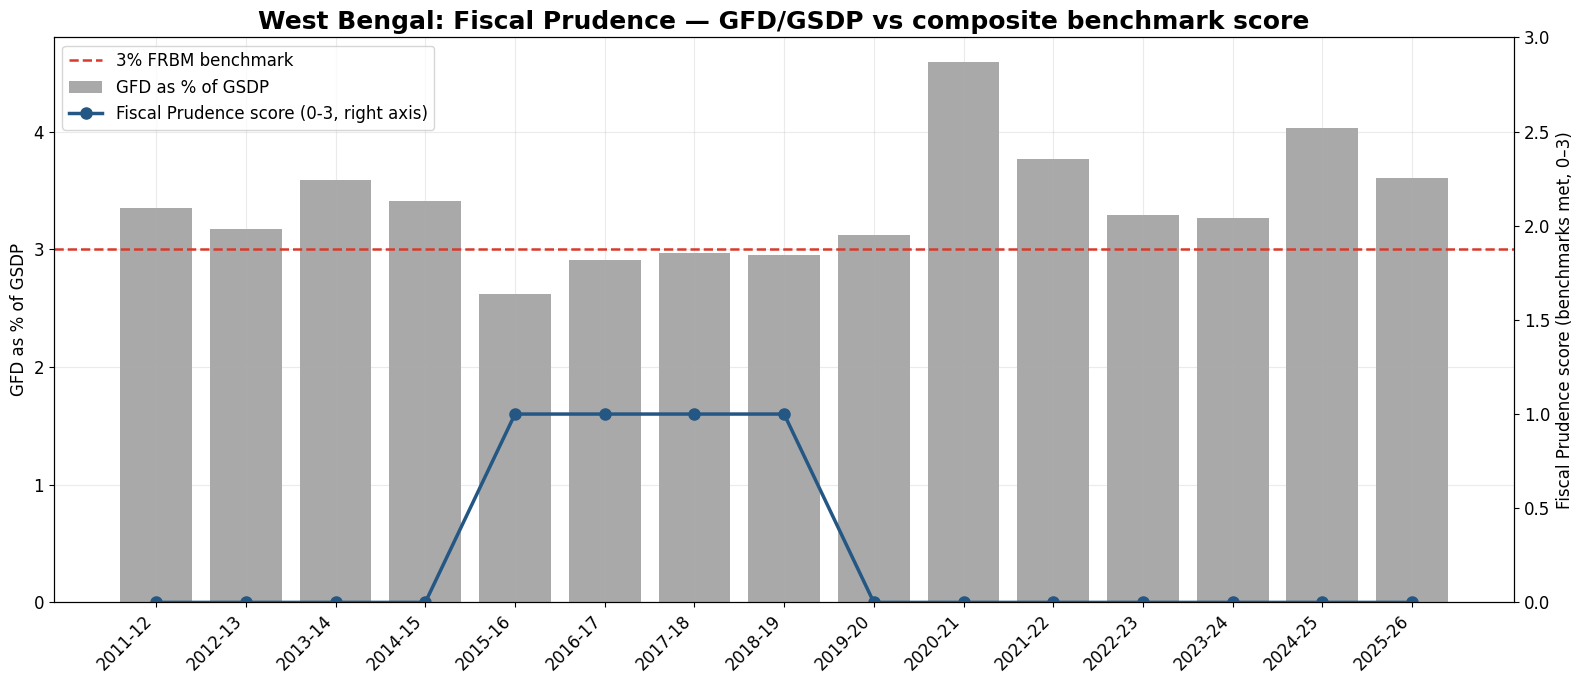

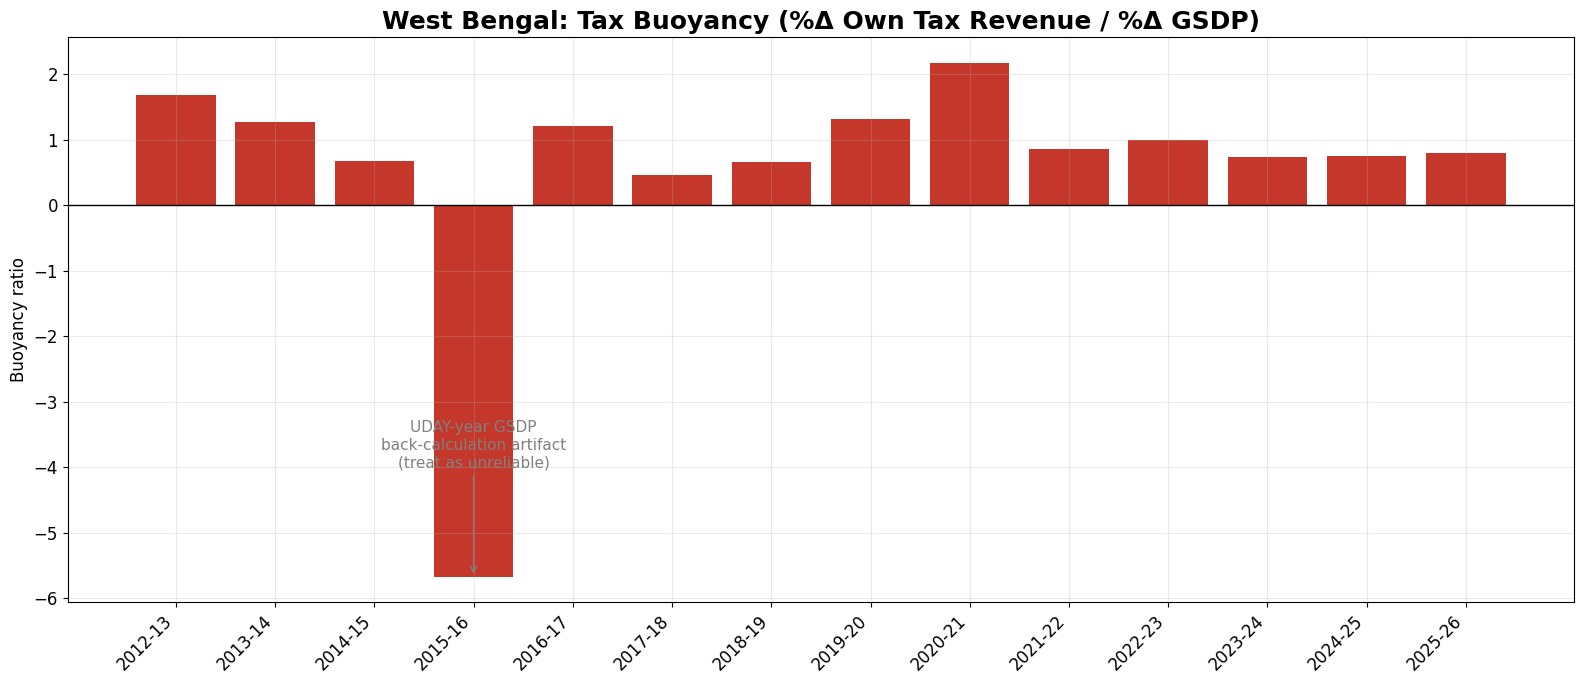

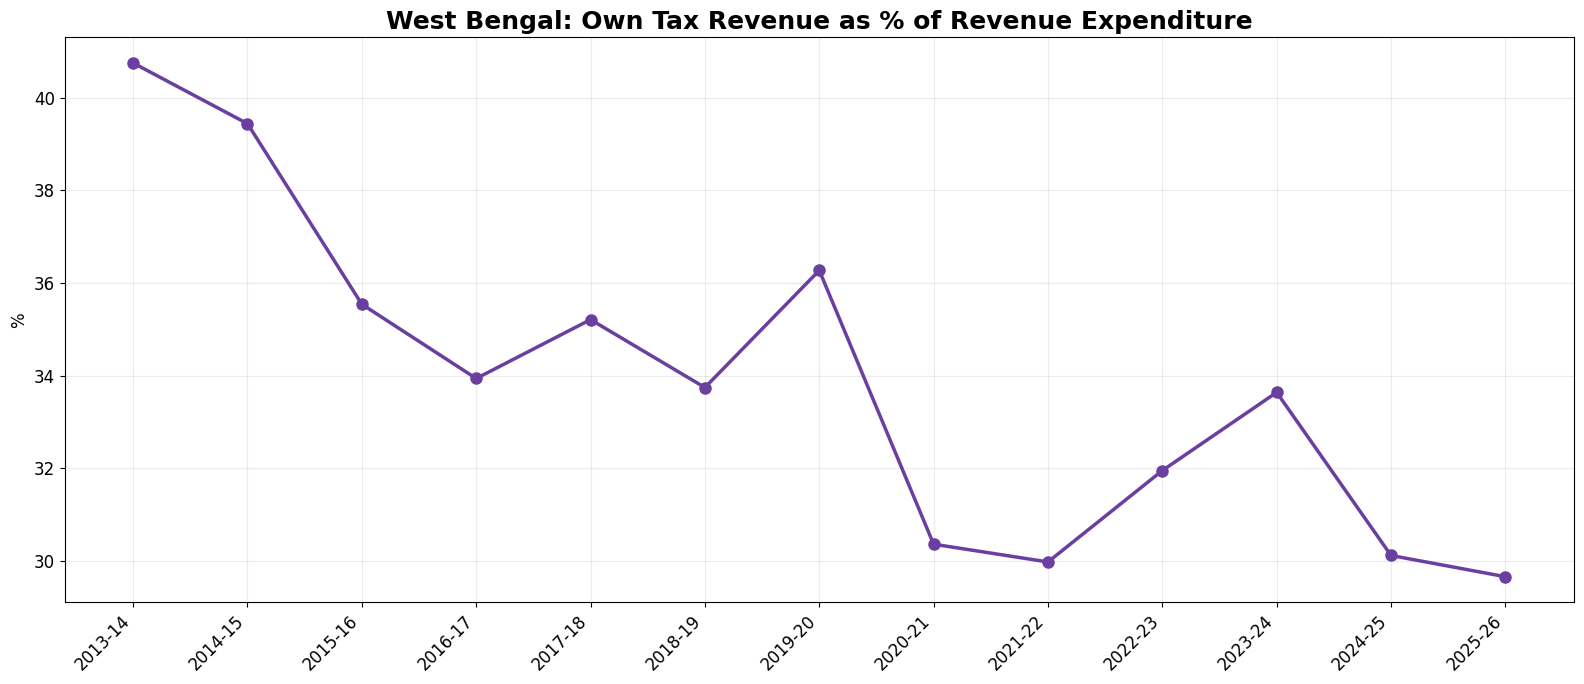

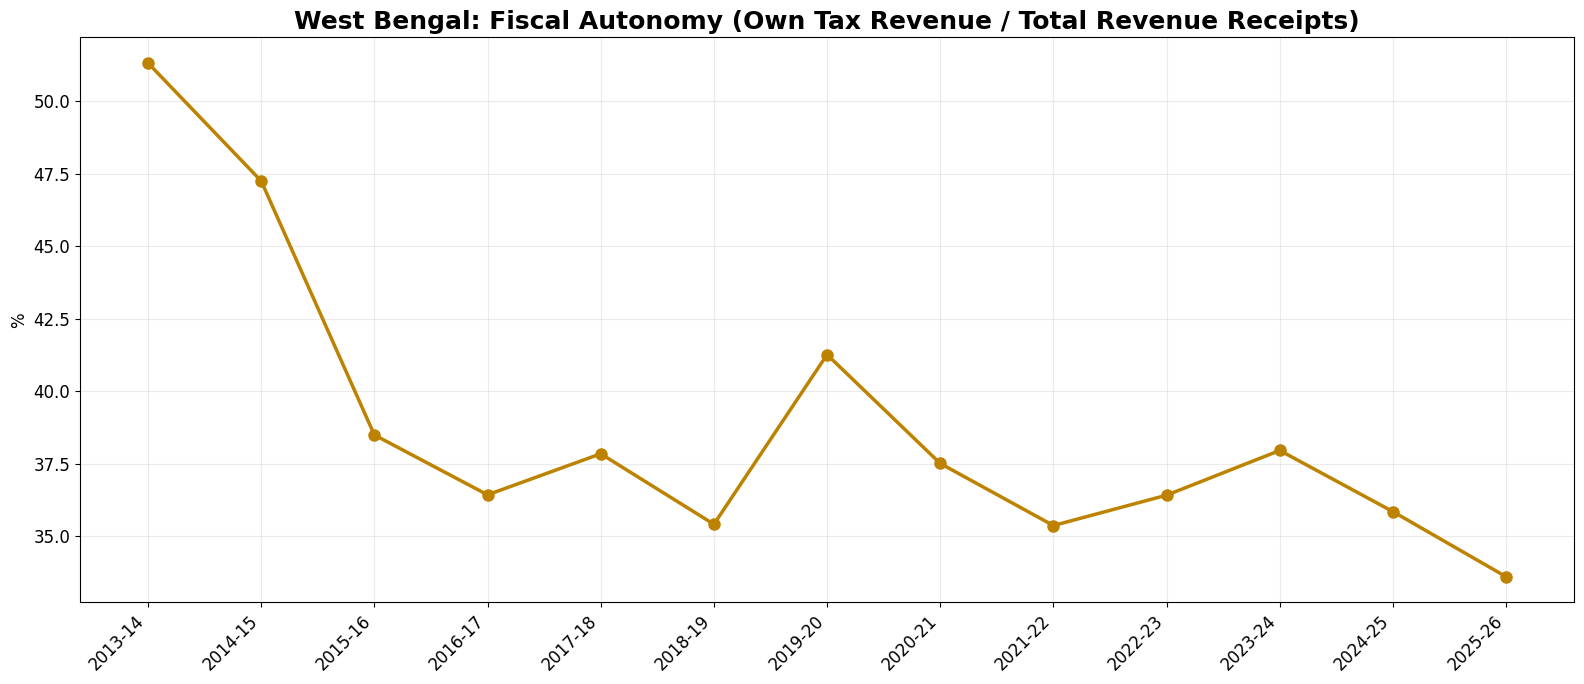

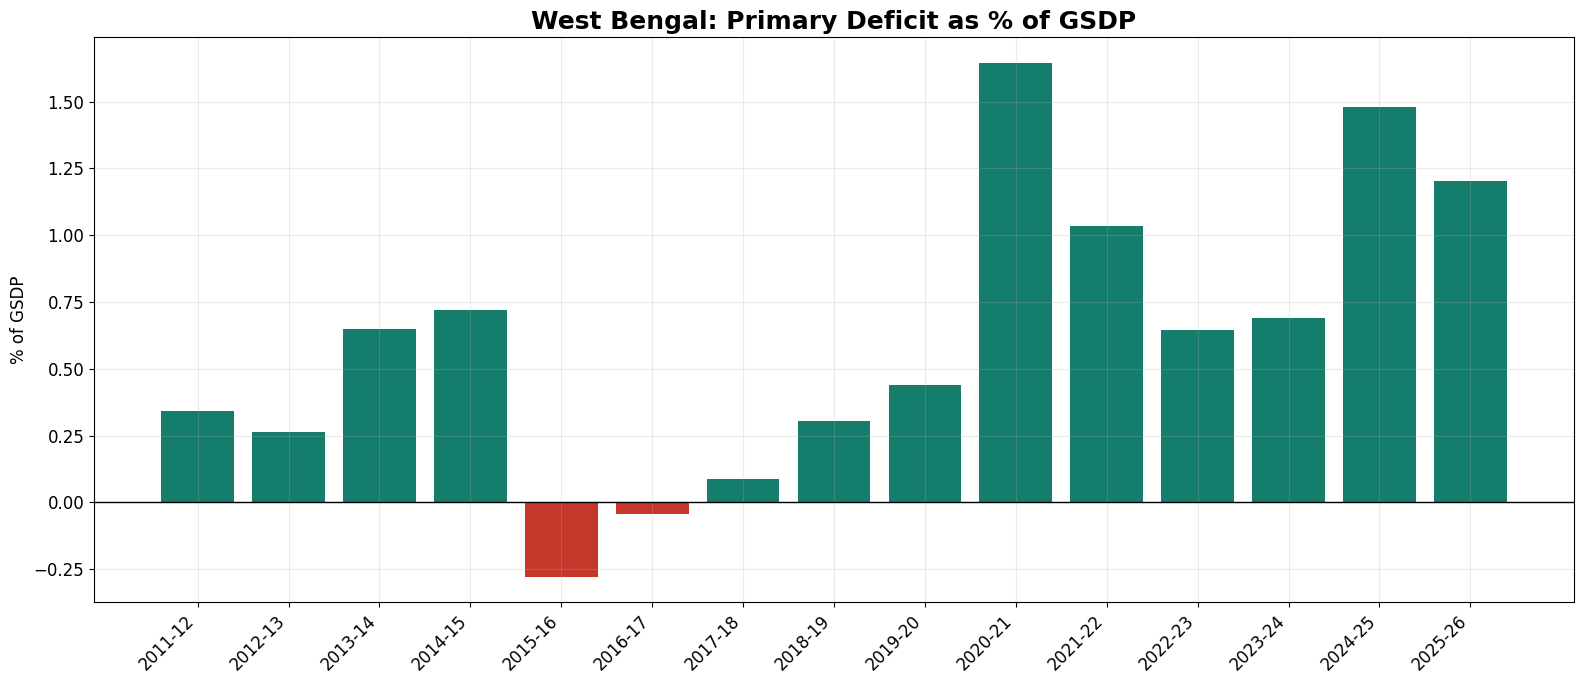

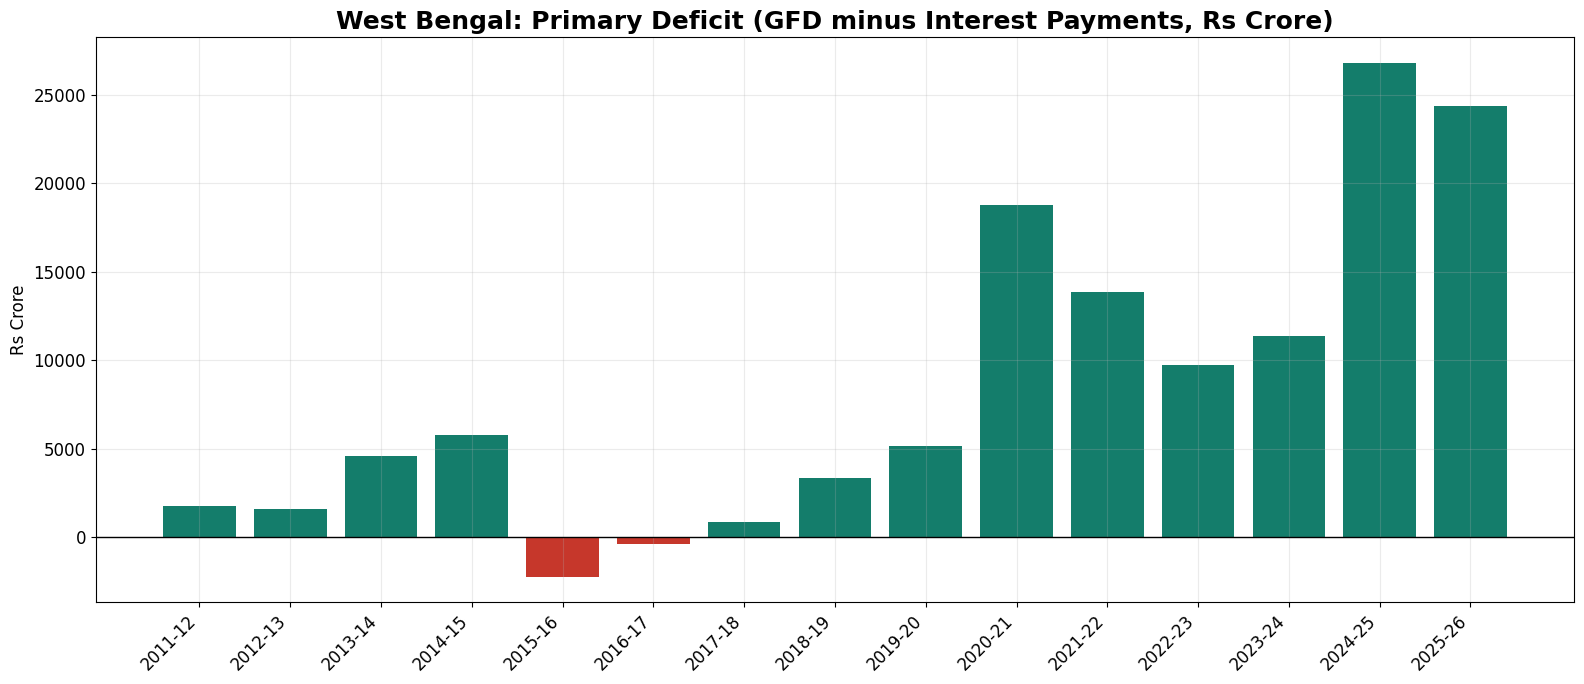

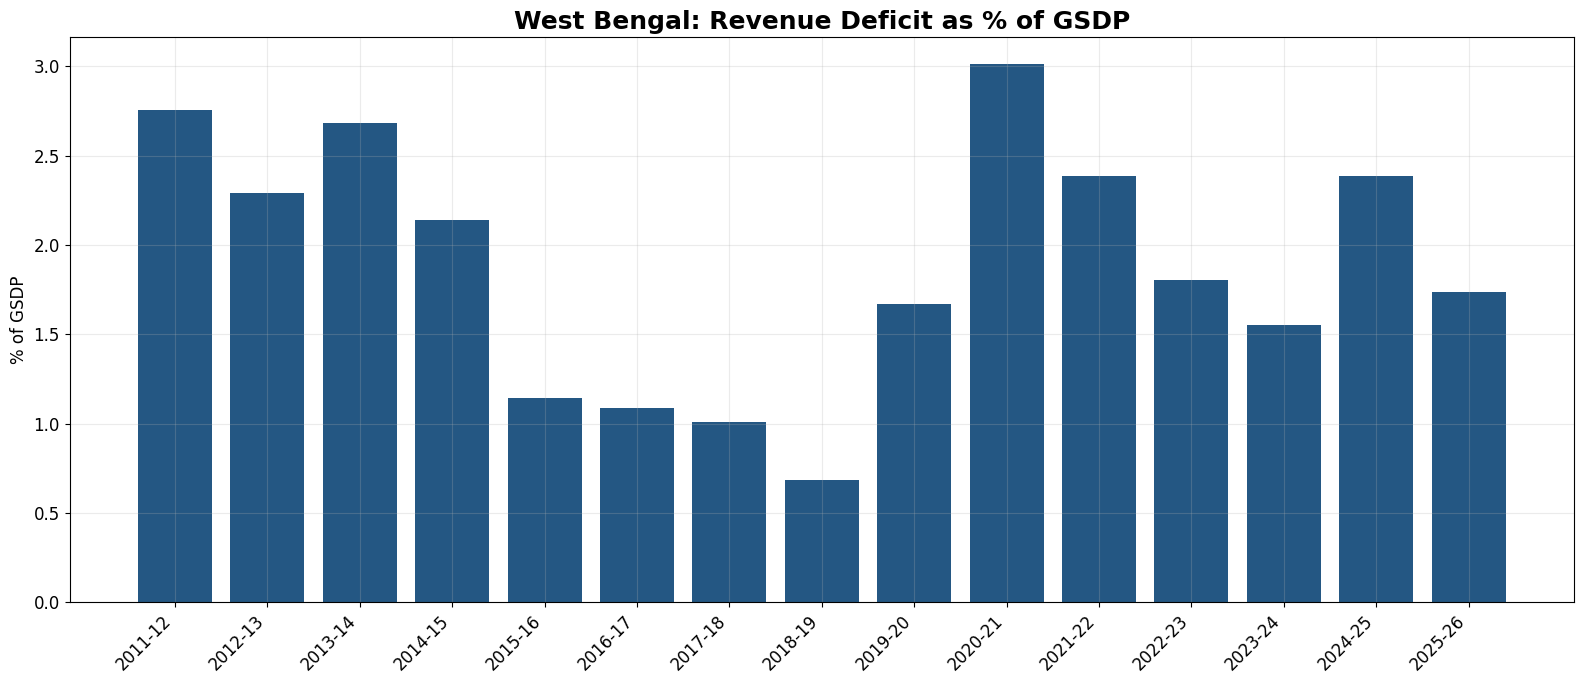

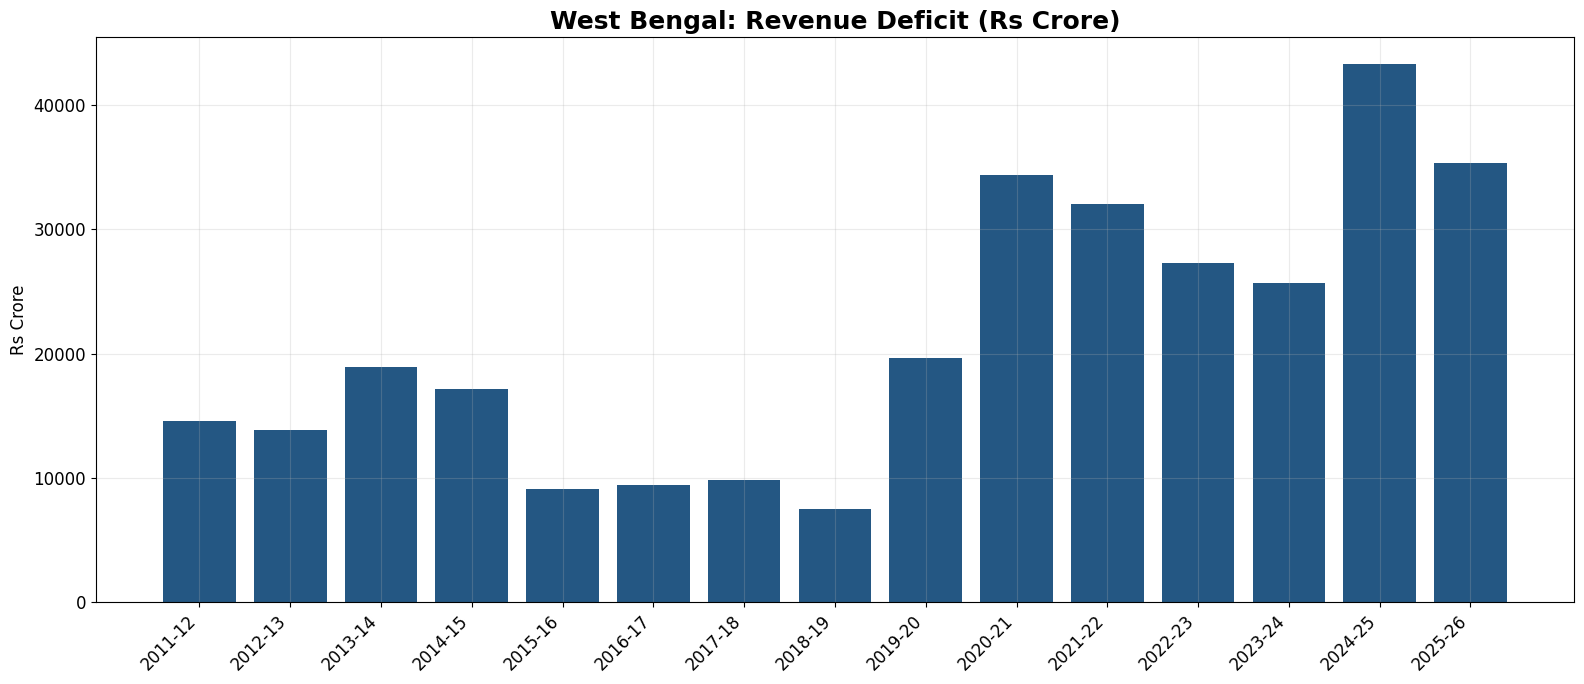


All 8 graphs have been generated.
Saved inside: WB_Fiscal_Graphs/


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. LOAD DATA
# ============================================================

file_path = "/content/wb_extended_indicators.csv"

df = pd.read_csv(file_path)

# Make sure years are treated as strings
df["fy"] = df["fy"].astype(str)

# Create output folder if required
import os
os.makedirs("WB_Fiscal_Graphs", exist_ok=True)


# ============================================================
# 2. GENERAL PLOTTING SETTINGS
# ============================================================

plt.rcParams["figure.figsize"] = (16, 7)
plt.rcParams["font.size"] = 12

years = df["fy"]


# ============================================================
# GRAPH 1
# WEST BENGAL: FISCAL PRUDENCE
# GFD/GSDP vs Composite Benchmark Score
# ============================================================

fig, ax1 = plt.subplots(figsize=(16, 7))

x = np.arange(len(df))

# ---- Left axis: GFD/GSDP ----
bars = ax1.bar(
    x,
    df["gfd_pct_gsdp"],
    width=0.8,
    color="darkgray",
    label="GFD as % of GSDP"
)

# 3% FRBM benchmark
ax1.axhline(
    3,
    color="#d83b2d",
    linestyle="--",
    linewidth=1.8,
    label="3% FRBM benchmark"
)

ax1.set_ylabel("GFD as % of GSDP")
ax1.set_ylim(0, 4.8)

ax1.set_xticks(x)
ax1.set_xticklabels(years, rotation=45, ha="right")

ax1.grid(
    axis="both",
    alpha=0.25
)

# ---- Right axis: Fiscal Prudence Score ----
ax2 = ax1.twinx()

ax2.plot(
    x,
    df["fiscal_prudence_score"],
    color="#245783",
    marker="o",
    linewidth=2.5,
    markersize=8,
    label="Fiscal Prudence score (0-3, right axis)"
)

ax2.set_ylabel(
    "Fiscal Prudence score (benchmarks met, 0–3)"
)

ax2.set_ylim(0, 3)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper left",
    frameon=True
)

plt.title(
    "West Bengal: Fiscal Prudence — GFD/GSDP vs composite benchmark score",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "WB_Fiscal_Graphs/8_fiscal_prudence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 2
# TAX BUOYANCY
# %Δ Own Tax Revenue / %Δ GSDP
# ============================================================

fig, ax = plt.subplots(figsize=(16, 7))

# Only years for which tax buoyancy exists
tax_df = df.dropna(subset=["tax_buoyancy"]).copy()

x_tax = np.arange(len(tax_df))

bars = ax.bar(
    x_tax,
    tax_df["tax_buoyancy"],
    width=0.8,
    color="#c6372b"
)

ax.axhline(
    0,
    color="black",
    linewidth=1
)

ax.set_xticks(x_tax)
ax.set_xticklabels(
    tax_df["fy"],
    rotation=45,
    ha="right"
)

ax.set_ylabel("Buoyancy ratio")

ax.set_title(
    "West Bengal: Tax Buoyancy (%Δ Own Tax Revenue / %Δ GSDP)",
    fontsize=18,
    fontweight="bold"
)

ax.grid(
    axis="both",
    alpha=0.25
)

# Highlight 2015-16
if "2015-16" in tax_df["fy"].values:

    idx = tax_df.index[tax_df["fy"] == "2015-16"][0]

    # Position within tax_df
    xpos = tax_df.index.get_loc(idx)

    ax.annotate(
        "UDAY-year GSDP\nback-calculation artifact\n(treat as unreliable)",
        xy=(xpos, tax_df.loc[idx, "tax_buoyancy"]),
        xytext=(xpos, -4.0),
        ha="center",
        fontsize=11,
        color="gray",
        arrowprops=dict(
            arrowstyle="->",
            color="gray"
        )
    )

plt.tight_layout()

plt.savefig(
    "WB_Fiscal_Graphs/7_tax_buoyancy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 3
# OWN TAX REVENUE AS % OF REVENUE EXPENDITURE
# ============================================================

fig, ax = plt.subplots(figsize=(16, 7))

tax_exp_df = df.dropna(
    subset=["tax_rev_to_rev_exp_pct"]
).copy()

x = np.arange(len(tax_exp_df))

ax.plot(
    x,
    tax_exp_df["tax_rev_to_rev_exp_pct"],
    color="#6a3fa0",
    marker="o",
    linewidth=2.5,
    markersize=8
)

ax.set_xticks(x)

ax.set_xticklabels(
    tax_exp_df["fy"],
    rotation=45,
    ha="right"
)

ax.set_ylabel("%")

ax.set_title(
    "West Bengal: Own Tax Revenue as % of Revenue Expenditure",
    fontsize=18,
    fontweight="bold"
)

ax.grid(
    axis="both",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "WB_Fiscal_Graphs/6_tax_to_revexp.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 4
# FISCAL AUTONOMY
# Own Tax Revenue / Total Revenue Receipts
# ============================================================

fig, ax = plt.subplots(figsize=(16, 7))

autonomy_df = df.dropna(
    subset=["fiscal_autonomy_pct"]
).copy()

x = np.arange(len(autonomy_df))

ax.plot(
    x,
    autonomy_df["fiscal_autonomy_pct"],
    color="#bd8200",
    marker="o",
    linewidth=2.5,
    markersize=8
)

ax.set_xticks(x)

ax.set_xticklabels(
    autonomy_df["fy"],
    rotation=45,
    ha="right"
)

ax.set_ylabel("%")

ax.set_title(
    "West Bengal: Fiscal Autonomy "
    "(Own Tax Revenue / Total Revenue Receipts)",
    fontsize=18,
    fontweight="bold"
)

ax.grid(
    axis="both",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "WB_Fiscal_Graphs/5_fiscal_autonomy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 5
# PRIMARY DEFICIT AS % OF GSDP
# ============================================================

fig, ax = plt.subplots(figsize=(16, 7))

values = df["primary_deficit_pct_gsdp"]

# Positive = green
# Negative = red
colors = [
    "#147d6b" if v >= 0 else "#c6372b"
    for v in values
]

ax.bar(
    x=np.arange(len(df)),
    height=values,
    color=colors,
    width=0.8
)

ax.axhline(
    0,
    color="black",
    linewidth=1
)

ax.set_xticks(np.arange(len(df)))

ax.set_xticklabels(
    df["fy"],
    rotation=45,
    ha="right"
)

ax.set_ylabel("% of GSDP")

ax.set_title(
    "West Bengal: Primary Deficit as % of GSDP",
    fontsize=18,
    fontweight="bold"
)

ax.grid(
    axis="both",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "WB_Fiscal_Graphs/4_primary_deficit_pct_gsdp.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 6
# PRIMARY DEFICIT
# GFD minus Interest Payments
# ============================================================

fig, ax = plt.subplots(figsize=(16, 7))

values = df["primary_deficit"]

colors = [
    "#147d6b" if v >= 0 else "#c6372b"
    for v in values
]

ax.bar(
    np.arange(len(df)),
    values,
    color=colors,
    width=0.8
)

ax.axhline(
    0,
    color="black",
    linewidth=1
)

ax.set_xticks(np.arange(len(df)))

ax.set_xticklabels(
    df["fy"],
    rotation=45,
    ha="right"
)

ax.set_ylabel("Rs Crore")

ax.set_title(
    "West Bengal: Primary Deficit "
    "(GFD minus Interest Payments, Rs Crore)",
    fontsize=18,
    fontweight="bold"
)

ax.grid(
    axis="both",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "WB_Fiscal_Graphs/3_primary_deficit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 7
# REVENUE DEFICIT AS % OF GSDP
# ============================================================

fig, ax = plt.subplots(figsize=(16, 7))

ax.bar(
    np.arange(len(df)),
    df["revenue_deficit_pct_gsdp"],
    color="#245783",
    width=0.8
)

ax.set_xticks(np.arange(len(df)))

ax.set_xticklabels(
    df["fy"],
    rotation=45,
    ha="right"
)

ax.set_ylabel("% of GSDP")

ax.set_title(
    "West Bengal: Revenue Deficit as % of GSDP",
    fontsize=18,
    fontweight="bold"
)

ax.grid(
    axis="both",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "WB_Fiscal_Graphs/2_revenue_deficit_pct_gsdp.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 8
# REVENUE DEFICIT
# Rs Crore
# ============================================================

fig, ax = plt.subplots(figsize=(16, 7))

ax.bar(
    np.arange(len(df)),
    df["revenue_deficit4"],
    color="#245783",
    width=0.8
)

ax.set_xticks(np.arange(len(df)))

ax.set_xticklabels(
    df["fy"],
    rotation=45,
    ha="right"
)

ax.set_ylabel("Rs Crore")

ax.set_title(
    "West Bengal: Revenue Deficit (Rs Crore)",
    fontsize=18,
    fontweight="bold"
)

ax.grid(
    axis="both",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "WB_Fiscal_Graphs/1_revenue_deficit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("\nAll 8 graphs have been generated.")
print("Saved inside: WB_Fiscal_Graphs/")

In [ ]:
import pandas as pd, numpy as np, matplotlib, os
matplotlib.use("Agg")
import matplotlib.pyplot as plt

plt.rcParams.update({"font.family":"DejaVu Sans","axes.spines.top":False,"axes.spines.right":False,
                     "axes.grid":True,"grid.alpha":.25,"figure.facecolor":"white"})
HERE = os.path.dirname(os.path.abspath("/content/fiscal_indicators_pct_gsdp.csv"))
OUT  = os.path.join(HERE, "figures"); os.makedirs(OUT, exist_ok=True) # Modified: Removed '..' to save figures in /content/figures
NAVY="#1F4E78"; RED="#C0392B"; GREY="#B0B0B0"; GOLD="#B7860B"; TEAL="#117864"; GREEN="#2E7D32"

d = pd.read_csv(os.path.join(HERE, "..", "data", "/content/fiscal_indicators_pct_gsdp.csv"))
d["interest_pct_gsdp"] = d["interest_payments"]/d["gsdp_est"]*100
d["capout_pct_gsdp"]   = d["capital_outlay"]/d["gsdp_est"]*100
d["revrec_pct_gsdp"]   = d["revenue_receipts"]/d["gsdp_est"]*100
d["revexp_pct_gsdp"]   = d["revenue_expenditure"]/d["gsdp_est"]*100
d["gfd_pct_gsdp"]      = d["gfd"]/d["gsdp_est"]*100
x = d["fy"].tolist()

def save(fig, name): fig.tight_layout(); fig.savefig(f"{OUT}/{name}.png", dpi=150); plt.close(fig)

# --- Exhibit 1: Debt/GSDP, WB vs All-India, 2006-2026 (Statement 19 & 20) ---
yrs=[2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026]
wb=[49.7,47.4,45.6,44,44,41.9,40.4,39.1,36.7,34.6,39.5,38.7,38.1,36.7,37.8,43.6,40.9,39.5,39.7,40,38.9]
ai=[31.1,28.9,26.6,26.1,25.5,23.5,22.8,22.2,22,21.7,23.7,25.1,25.1,25.3,26.6,31,29.1,28.2,28.1,28.4,29.2]
fig, ax = plt.subplots(figsize=(11,5))
ax.plot(yrs, wb, marker="o", color=NAVY, lw=2.2, label="West Bengal")
ax.plot(yrs, ai, marker="s", color=GREY, lw=2, label="All-States average")
ax.fill_between(yrs, wb, ai, color=NAVY, alpha=.10)
ax.axvline(2011, color=RED, ls="--", lw=1.3); ax.text(2011.15, 48, "WB FRBM Act\n(2010)", color=RED, fontsize=8)
ax.axvline(2016, color=GOLD, ls=":", lw=1.5); ax.text(2016.15, 31, "UDAY", color=GOLD, fontsize=8)
ax.axvline(2021, color=TEAL, ls=":", lw=1.5); ax.text(2021.15, 46, "COVID", color=TEAL, fontsize=8)
ax.set_ylabel("Outstanding liabilities, % of GSDP"); ax.set_xlabel("As at end-March")
ax.set_title("The 20-year spine: WB debt never converges to the national average", fontsize=13, weight="bold")
ax.legend(); save(fig, "s1_debt")

# --- Exhibit 2: Three deficits vs FRBM targets ---
fig, ax = plt.subplots(figsize=(11,5))
ax.plot(x, d["gfd_pct_gsdp"], marker="o", color=NAVY, lw=2, label="Gross Fiscal Deficit")
ax.plot(x, d["revenue_deficit4"]/d["gsdp_est"]*100, marker="s", color=RED, lw=2, label="Revenue Deficit")
ax.plot(x, (d["gfd"]-d["interest_payments"])/d["gsdp_est"]*100, marker="^", color=TEAL, lw=2, label="Primary Deficit")
ax.axhline(3, color=RED, ls="--", lw=1, alpha=.7); ax.text(0.2, 3.08, "FRBM ceiling: GFD 3% of GSDP", color=RED, fontsize=8)
ax.axhline(0, color="black", lw=.8); ax.text(0.2, .08, "FRBM target: Revenue Deficit = 0", color="black", fontsize=8)
ax.set_ylabel("% of GSDP"); ax.set_xticks(range(len(x))); ax.set_xticklabels(x, rotation=45, ha="right", fontsize=8)
ax.set_title("Three deficits against two FRBM targets", fontsize=13, weight="bold"); ax.legend()
save(fig, "s2_deficits")

# --- Exhibit 5: Interest payments vs capital outlay, %GSDP ---
fig, ax = plt.subplots(figsize=(11,5))
ax.bar(x, d["interest_pct_gsdp"], color=RED, alpha=.85, label="Interest payments")
ax.bar(x, d["capout_pct_gsdp"], bottom=d["interest_pct_gsdp"], color=GREEN, alpha=.85, label="Capital outlay")
ax.set_ylabel("% of GSDP"); ax.set_xticks(range(len(x))); ax.set_xticklabels(x, rotation=45, ha="right", fontsize=8)
ax.set_title("Servicing the past vs building the future (% of GSDP)", fontsize=13, weight="bold"); ax.legend()
save(fig, "s3_int_cap")

# --- Exhibit 3(mechanism): Revenue scissors ---
m = d["revrec_pct_gsdp"].notna()
fig, ax = plt.subplots(figsize=(11,5))
ax.plot(d.loc[m,"fy"], d.loc[m,"revexp_pct_gsdp"], marker="o", color=RED, lw=2.2, label="Revenue expenditure")
ax.plot(d.loc[m,"fy"], d.loc[m,"revrec_pct_gsdp"], marker="s", color=NAVY, lw=2.2, label="Revenue receipts")
ax.fill_between(range(m.sum()), d.loc[m,"revrec_pct_gsdp"], d.loc[m,"revexp_pct_gsdp"], color=RED, alpha=.13)
ax.set_ylabel("% of GSDP"); ax.tick_params(axis="x", rotation=45, labelsize=8)
ax.set_title("The revenue scissors: the gap IS the revenue deficit", fontsize=13, weight="bold"); ax.legend()
save(fig, "s4_scissors")

# --- Exhibit 4: Own tax revenue, %GSDP ---
fig, ax = plt.subplots(figsize=(11,4.6))
ax.plot(x, d["own_tax_pct_gsdp"], marker="o", color=GOLD, lw=2.4)
ax.axhspan(4.4, 5.4, color=GOLD, alpha=.10)
ax.set_ylim(3.5, 6); ax.set_ylabel("Own tax revenue, % of GSDP")
ax.tick_params(axis="x", rotation=45, labelsize=8)
ax.set_title("The binding constraint: own tax revenue stuck in a 1-point band for 15 years", fontsize=12.5, weight="bold")
save(fig, "s5_owntax")

# --- Exhibit 6: Budgeted vs actual revenue-deficit share of GFD (fiscal marksmanship) ---
fy=["2012-13","2013-14","2014-15","2015-16","2016-17","2017-18","2019-20","2021-22","2023-24"]
be=[43.8,26.0,0,0,0,0,0,44.0,47.0]; ac=[72.2,74.6,62.7,43.6,37.4,33.9,53.4,63.3,47.6]
i = np.arange(len(fy)); w=.38
fig, ax = plt.subplots(figsize=(11,5))
ax.bar(i-w/2, be, w, color=GREY, label="Budgeted (BE)")
ax.bar(i+w/2, ac, w, color=RED, label="Actual (Accounts)")
for k in range(len(fy)):
    ax.annotate("", xy=(i[k]+w/2, ac[k]), xytext=(i[k]-w/2, be[k]), arrowprops=dict(arrowstyle="->", color="gray", lw=.9))
ax.set_xticks(i); ax.set_xticklabels(fy, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Revenue deficit as % of GFD")
ax.set_title("Fiscal marksmanship: budgeting zero revenue deficit, delivering 34-75%", fontsize=13, weight="bold")
ax.legend(); save(fig, "s6_marksmanship")

# --- Exhibit 8: Fiscal Prudence (composite score is Claude's own construction -- see README) ---
def prudence(row):
    score = 0
    if row["gfd_pct_gsdp"] <= 3: score += 1
    if row["revenue_deficit4"] <= 0: score += 1
    debt = {"2011-12":41.9,"2012-13":40.4,"2013-14":39.1,"2014-15":36.7,"2015-16":34.6,"2016-17":39.5,
            "2017-18":38.7,"2018-19":38.1,"2019-20":36.7,"2020-21":37.8,"2021-22":43.6,"2022-23":40.9,
            "2023-24":39.5,"2024-25":39.7,"2025-26":38.9}.get(row["fy"], np.nan)
    if pd.notna(debt) and debt <= 25: score += 1
    return score
d["fiscal_prudence_score"] = d.apply(prudence, axis=1)
fig, ax1 = plt.subplots(figsize=(12,6))
ax1.bar(x, d["gfd_pct_gsdp"], color="#B0B0B0", label="GFD as % of GSDP (left axis)")
ax1.axhline(3, color=RED, ls="--", lw=1.2, label="3% FRBM benchmark")
ax1.set_ylabel("GFD as % of GSDP"); ax1.set_xticks(range(len(x))); ax1.set_xticklabels(x, rotation=45, ha="right", fontsize=8)
ax2 = ax1.twinx()
ax2.plot(x, d["fiscal_prudence_score"], color=NAVY, marker="o", lw=2, label="Fiscal Prudence score (0-3, right axis)")
ax2.set_ylabel("Fiscal Prudence score (benchmarks met, 0-3)"); ax2.set_yticks([0,1,2,3]); ax2.set_ylim(0,3)
l1,b1 = ax1.get_legend_handles_labels(); l2,b2 = ax2.get_legend_handles_labels()
ax1.legend(l1+l2, b1+b2, loc="upper left", fontsize=8)
ax1.set_title("West Bengal: Fiscal Prudence -- GFD/GSDP vs composite benchmark score", fontsize=13, weight="bold")
save(fig, "8_fiscal_prudence")

print("Fiscal charts written to", OUT)

In [ ]:
#ODISHA COMPARISON FISCAL CHARTS

In [2]:
import pandas as pd, numpy as np, matplotlib, os
matplotlib.use("Agg")
import matplotlib.pyplot as plt

plt.rcParams.update({"font.family":"DejaVu Sans","axes.spines.top":False,"axes.spines.right":False,
                     "axes.grid":True,"grid.alpha":.25,"figure.facecolor":"white"})
OUT = "/content/WB_Fiscal_Graphs"; os.makedirs(OUT, exist_ok=True)
NAVY="#1F4E78"; RED="#C0392B"; GREY="#B0B0B0"; GOLD="#B7860B"; TEAL="#117864"; GREEN="#2E7D32"; ORANGE="#E67E22"

o = pd.read_csv("/content/odisha_indicators.csv")
w = pd.read_csv("/content/odisha_indicators.csv")
w["revenue_deficit_pct_gsdp"] = w["revenue_deficit4"]/w["gsdp_est"]*100
w["gfd_pct_gsdp"] = w["gfd"]/w["gsdp_est"]*100
x_o = o["fy"].tolist()

def save(fig,name): fig.tight_layout(); fig.savefig(f"{OUT}/{name}.png", dpi=150); plt.close(fig)

# ---------- 1. Debt/GSDP: Odisha vs WB vs All-India ----------
yrs=[2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026]
wb =[49.7,47.4,45.6,44,44,41.9,40.4,39.1,36.7,34.6,39.5,38.7,38.1,36.7,37.8,43.6,40.9,39.5,39.7,40,38.9]
od =[47.9,42.2,33.2,29.6,28.1,23.8,20.7,18.8,17.0,16.2,19.9,18.3,23.4,21.2,26.8,26.1,20.0,19.6,19.7,20.6,20.3]
ai =[31.1,28.9,26.6,26.1,25.5,23.5,22.8,22.2,22.0,21.7,23.7,25.1,25.1,25.3,26.6,31.0,29.1,28.2,28.1,28.4,29.2]
fig, ax = plt.subplots(figsize=(11,5.5))
ax.plot(yrs, wb, marker="o", color=RED, lw=2.2, label="West Bengal")
ax.plot(yrs, od, marker="^", color=GREEN, lw=2.2, label="Odisha")
ax.plot(yrs, ai, marker="s", color=GREY, lw=1.8, ls="--", label="All-States average")
ax.axvline(2011, color="gray", ls=":", lw=1)
ax.set_ylabel("Outstanding liabilities, % of GSDP"); ax.set_xlabel("As at end-March")
ax.set_title("Two states, two trajectories: Odisha converges below the national average; WB never does", fontsize=12.5, weight="bold")
ax.legend(); save(fig, "cmp1_debt_wb_odisha")

# ---------- 2. Revenue deficit %GSDP: Odisha vs WB ----------
fig, ax = plt.subplots(figsize=(11,5.5))
ax.plot(w["fy"], w["revenue_deficit_pct_gsdp"], marker="o", color=RED, lw=2, label="West Bengal (deficit)")
ax.plot(o["fy"], o["revenue_deficit_pct_gsdp"], marker="^", color=GREEN, lw=2, label="Odisha (surplus, shown as negative)")
ax.axhline(0, color="black", lw=1)
ax.set_ylabel("Revenue deficit(+) / surplus(-), % of GSDP")
ax.tick_params(axis="x", rotation=45, labelsize=8)
ax.set_title("West Bengal borrows to cover consumption. Odisha has run a revenue surplus every year since 2011-12.", fontsize=12, weight="bold")
ax.legend(); save(fig, "cmp2_revdef_wb_odisha")

# ---------- 3. GFD %GSDP: Odisha vs WB, with FRBM 3% line ----------
fig, ax = plt.subplots(figsize=(11,5))
ax.plot(w["fy"], w["gfd_pct_gsdp"], marker="o", color=RED, lw=2, label="West Bengal")
ax.plot(o["fy"], o["gfd_pct_gsdp"], marker="^", color=GREEN, lw=2, label="Odisha")
ax.axhline(3, color="gray", ls="--", lw=1.2); ax.text(0.2,3.1,"3% FRBM ceiling", fontsize=8, color="gray")
ax.axhline(0, color="black", lw=.8)
ax.set_ylabel("Gross Fiscal Deficit, % of GSDP"); ax.tick_params(axis="x", rotation=45, labelsize=8)
ax.set_title("Odisha ran an outright fiscal SURPLUS in 2021-22 -- rare among Indian states", fontsize=12.5, weight="bold")
ax.legend(); save(fig, "cmp3_gfd_wb_odisha")

# ---------- 4. Odisha standalone: three deficits ----------
fig, ax = plt.subplots(figsize=(11,5))
ax.plot(x_o, o["gfd_pct_gsdp"], marker="o", color=NAVY, lw=2, label="Gross Fiscal Deficit")
ax.plot(x_o, o["revenue_deficit_pct_gsdp"], marker="s", color=RED, lw=2, label="Revenue Deficit (negative = surplus)")
ax.plot(x_o, o["primary_deficit_pct_gsdp"], marker="^", color=TEAL, lw=2, label="Primary Deficit")
ax.axhline(3, color=RED, ls="--", lw=1, alpha=.6); ax.axhline(0, color="black", lw=.8)
ax.set_ylabel("% of GSDP"); ax.tick_params(axis="x", rotation=45, labelsize=8)
ax.set_title("Odisha: three deficits, mostly on the right side of zero", fontsize=13, weight="bold")
ax.legend(); save(fig, "o1_deficits")

# ---------- 5. Odisha: interest vs capital outlay ----------
o["interest_pct_gsdp"] = o["interest_payments"]/o["gsdp_est"]*100
o["capout_pct_gsdp"] = o["capital_outlay"]/o["gsdp_est"]*100
fig, ax = plt.subplots(figsize=(11,5))
ax.bar(x_o, o["interest_pct_gsdp"], color=RED, alpha=.85, label="Interest payments")
ax.bar(x_o, o["capout_pct_gsdp"], bottom=o["interest_pct_gsdp"], color=GREEN, alpha=.85, label="Capital outlay")
ax.set_ylabel("% of GSDP"); ax.tick_params(axis="x", rotation=45, labelsize=8)
ax.set_title("Odisha: capital outlay dwarfs interest payments (~2x-4x most years)", fontsize=13, weight="bold")
ax.legend(); save(fig, "o2_int_cap")

# ---------- 6. Odisha own tax revenue %GSDP (with WB overlay -- the paradox chart) ----------
fig, ax = plt.subplots(figsize=(11,5))
ax.plot(x_o, o["own_tax_pct_gsdp"], marker="o", color=GOLD, lw=2.2, label="Odisha")
ax.plot(w["fy"], w["own_tax_pct_gsdp"], marker="s", color=NAVY, lw=2.2, label="West Bengal")
ax.set_ylabel("Own tax revenue, % of GSDP"); ax.tick_params(axis="x", rotation=45, labelsize=8)
ax.set_title("The paradox: Odisha's own-TAX effort is lower than WB's, yet Odisha runs surpluses\n(the gap is non-tax revenue -- mining royalties)", fontsize=12, weight="bold")
ax.legend(); save(fig, "o3_owntax_paradox")

# ---------- 7. Fiscal autonomy comparison ----------
m = o["fiscal_autonomy_pct"].notna()
mw = w["fiscal_autonomy_pct"].notna()
fig, ax = plt.subplots(figsize=(11,5))
ax.plot(o.loc[m,"fy"], o.loc[m,"fiscal_autonomy_pct"], marker="o", color=GOLD, lw=2.2, label="Odisha (own TAX rev / total revenue receipts)")
ax.plot(w.loc[mw,"fy"], w.loc[mw,"fiscal_autonomy_pct"], marker="s", color=NAVY, lw=2.2, label="West Bengal (same measure)")
ax.set_ylabel("%"); ax.tick_params(axis="x", rotation=45, labelsize=8)
ax.set_title("Odisha looks LESS fiscally autonomous by this narrow tax-only measure --\nbut its total revenue base (tax + mining non-tax) is what actually balances the budget", fontsize=11.5, weight="bold")
ax.legend(fontsize=8); save(fig, "o4_fiscal_autonomy")

print("Odisha figures written to", OUT)
print(os.listdir(OUT))

Odisha figures written to /content/WB_Fiscal_Graphs
['1_revenue_deficit.png', 'o4_fiscal_autonomy.png', '7_tax_buoyancy.png', '8_fiscal_prudence.png', 'cmp3_gfd_wb_odisha.png', 'o3_owntax_paradox.png', 'cmp2_revdef_wb_odisha.png', 'o1_deficits.png', 'o2_int_cap.png', '5_fiscal_autonomy.png', '3_primary_deficit.png', '6_tax_to_revexp.png', 'cmp1_debt_wb_odisha.png', '2_revenue_deficit_pct_gsdp.png', '4_primary_deficit_pct_gsdp.png']


In [ ]:
#ODISHA NLP

In [ ]:
# ============================================
# ODISHA BUDGET NLP PROJECT
# ============================================

!apt-get update -qq
!apt-get install -y -qq poppler-utils tesseract-ocr

!pip install -q pymupdf pytesseract pandas openpyxl matplotlib seaborn

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package poppler-utils.
(Reading database ... 122809 files and directories currently installed.)
Preparing to unpack .../poppler-utils_24.02.0-1ubuntu9.9_amd64.deb ...
Unpacking poppler-utils (24.02.0-1ubuntu9.9) ...
Setting up poppler-utils (24.02.0-1ubuntu9.9) ...
Processing triggers for man-db (2.12.0-4build2) ...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 60.9 MB/s eta 0:00:00


In [ ]:
import os

os.makedirs("/content/ODISHA", exist_ok=True)

print("ODISHA folder created.")
print("/content/ODISHA")

ODISHA folder created.
/content/ODISHA


In [ ]:
import os

folder = "/content/ODISHA"

files_in_folder = sorted(os.listdir(folder))

print("Total files:", len(files_in_folder))
print()

for f in files_in_folder:
    print(f)

Total files: 22

Odisha_2005.pdf
Odisha_2006.pdf
Odisha_2007.pdf
Odisha_2008.pdf
Odisha_2009.pdf
Odisha_2010.pdf
Odisha_2011.pdf
Odisha_2012.pdf
Odisha_2013.pdf
Odisha_2014.pdf
Odisha_2015.pdf
Odisha_2016.pdf
Odisha_2017.pdf
Odisha_2018.pdf
Odisha_2019.pdf
Odisha_2020.pdf
Odisha_2021.pdf
Odisha_2022.pdf
Odisha_2023.pdf
Odisha_2024.pdf
Odisha_2025.pdf
Odisha_2026.pdf


In [ ]:
import re

expected_years = list(range(2005, 2027))

year_files = {}

for filename in files_in_folder:

    if not filename.lower().endswith(".pdf"):
        continue

    match = re.search(r'20\d{2}', filename)

    if match:
        year = int(match.group())

        if year in expected_years:
            year_files[year] = os.path.join(folder, filename)

print("YEAR CHECK")
print("=" * 60)

for year in expected_years:

    if year in year_files:
        print(f"✅ {year} → {os.path.basename(year_files[year])}")
    else:
        print(f"❌ {year} → MISSING")

print("=" * 60)

missing_years = [
    year for year in expected_years
    if year not in year_files
]

print("Missing years:", missing_years)
print("Total years found:", len(year_files))

YEAR CHECK
✅ 2005 → Odisha_2005.pdf
✅ 2006 → Odisha_2006.pdf
✅ 2007 → Odisha_2007.pdf
✅ 2008 → Odisha_2008.pdf
✅ 2009 → Odisha_2009.pdf
✅ 2010 → Odisha_2010.pdf
✅ 2011 → Odisha_2011.pdf
✅ 2012 → Odisha_2012.pdf
✅ 2013 → Odisha_2013.pdf
✅ 2014 → Odisha_2014.pdf
✅ 2015 → Odisha_2015.pdf
✅ 2016 → Odisha_2016.pdf
✅ 2017 → Odisha_2017.pdf
✅ 2018 → Odisha_2018.pdf
✅ 2019 → Odisha_2019.pdf
✅ 2020 → Odisha_2020.pdf
✅ 2021 → Odisha_2021.pdf
✅ 2022 → Odisha_2022.pdf
✅ 2023 → Odisha_2023.pdf
✅ 2024 → Odisha_2024.pdf
✅ 2025 → Odisha_2025.pdf
✅ 2026 → Odisha_2026.pdf
Missing years: []
Total years found: 22


In [ ]:
# ============================================
# ODISHA BUDGET SPEECH
# STEP 6: TEXT EXTRACTION + OCR FALLBACK
# ============================================

import pymupdf
import pytesseract
from PIL import Image
import os
import pandas as pd

# Create folder for extracted text
text_folder = "/content/ODISHA_TEXT"
os.makedirs(text_folder, exist_ok=True)


# --------------------------------------------
# NORMAL PDF TEXT EXTRACTION
# --------------------------------------------

def extract_pdf_text(pdf_path):
    doc = pymupdf.open(pdf_path)

    pages_text = []

    for page in doc:
        pages_text.append(page.get_text())

    doc.close()

    return "\n".join(pages_text)


# --------------------------------------------
# OCR FUNCTION
# --------------------------------------------

def ocr_pdf(pdf_path, dpi=200):

    doc = pymupdf.open(pdf_path)

    pages_text = []

    total_pages = len(doc)

    for i, page in enumerate(doc):

        pix = page.get_pixmap(
            dpi=dpi,
            alpha=False
        )

        img = Image.frombytes(
            "RGB",
            [pix.width, pix.height],
            pix.samples
        )

        text = pytesseract.image_to_string(img)

        pages_text.append(text)

        print(
            f"OCR page {i+1}/{total_pages}",
            end="\r"
        )

    doc.close()

    print()

    return "\n".join(pages_text)


# --------------------------------------------
# PROCESS ALL YEARS
# --------------------------------------------

extraction_results = []

for year in expected_years:

    pdf_path = year_files[year]

    print("\n" + "=" * 70)
    print(f"PROCESSING ODISHA {year}")
    print("=" * 70)

    # First try normal PDF extraction
    text = extract_pdf_text(pdf_path)

    word_count = len(text.split())

    print("Normal extraction word count:", word_count)

    # If extraction is too small, use OCR
    if word_count < 500:

        print("⚠️ Insufficient text detected.")
        print("Running OCR...")

        text = ocr_pdf(pdf_path)

        word_count = len(text.split())

        method = "OCR"

    else:

        method = "PDF text"

    # Save extracted text
    text_file = os.path.join(
        text_folder,
        f"Odisha_{year}.txt"
    )

    with open(
        text_file,
        "w",
        encoding="utf-8"
    ) as f:

        f.write(text)

    extraction_results.append({
        "year": year,
        "filename": os.path.basename(pdf_path),
        "words": word_count,
        "method": method
    })

    print("Final word count:", word_count)
    print("Extraction method:", method)

    if word_count < 500:
        print("❌ WARNING: Very little text extracted")
    else:
        print("✅ Extraction successful")


# --------------------------------------------
# CREATE EXTRACTION CHECK TABLE
# --------------------------------------------

extraction_df = pd.DataFrame(
    extraction_results
)

extraction_df = extraction_df.sort_values(
    "year"
).reset_index(drop=True)

print("\n\nFINAL EXTRACTION CHECK")
print("=" * 70)

display(extraction_df)


PROCESSING ODISHA 2005
Normal extraction word count: 13159
Final word count: 13159
Extraction method: PDF text
✅ Extraction successful

PROCESSING ODISHA 2006
Normal extraction word count: 7505
Final word count: 7505
Extraction method: PDF text
✅ Extraction successful

PROCESSING ODISHA 2007
Normal extraction word count: 4868
Final word count: 4868
Extraction method: PDF text
✅ Extraction successful

PROCESSING ODISHA 2008
Normal extraction word count: 7764
Final word count: 7764
Extraction method: PDF text
✅ Extraction successful

PROCESSING ODISHA 2009
Normal extraction word count: 4907
Final word count: 4907
Extraction method: PDF text
✅ Extraction successful

PROCESSING ODISHA 2010
Normal extraction word count: 2666
Final word count: 2666
Extraction method: PDF text
✅ Extraction successful

PROCESSING ODISHA 2011
Normal extraction word count: 9129
Final word count: 9129
Extraction method: PDF text
✅ Extraction successful

PROCESSING ODISHA 2012
Normal extraction word count: 7785
F

,year,filename,words,method
0,2005,Odisha_2005.pdf,13159,PDF text
1,2006,Odisha_2006.pdf,7505,PDF text
2,2007,Odisha_2007.pdf,4868,PDF text
3,2008,Odisha_2008.pdf,7764,PDF text
4,2009,Odisha_2009.pdf,4907,PDF text
5,2010,Odisha_2010.pdf,2666,PDF text
6,2011,Odisha_2011.pdf,9129,PDF text
7,2012,Odisha_2012.pdf,7785,PDF text
8,2013,Odisha_2013.pdf,79065,PDF text
9,2014,Odisha_2014.pdf,83339,PDF text


In [ ]:
# ============================================
# ODISHA BUDGET NLP
# STEP 7: KEYWORD DICTIONARIES
# ============================================

import re
import pandas as pd
import os

# --------------------------------------------
# POLICY KEYWORDS
# --------------------------------------------

policy_keywords = {

    "agriculture": [
        r"\bagriculture\b",
        r"\bagricultural\b",
        r"\bfarmers?\b",
        r"\bfarming\b",
        r"\bcrop[s]?\b",
        r"\birrigation\b"
    ],

    "education": [
        r"\beducation\b",
        r"\bschool[s]?\b",
        r"\bcollege[s]?\b",
        r"\buniversity\b",
        r"\buniversities\b",
        r"\bstudent[s]?\b",
        r"\bliteracy\b"
    ],

    "health": [
        r"\bhealth\b",
        r"\bhealthcare\b",
        r"\bhospital[s]?\b",
        r"\bmedical\b",
        r"\bdoctor[s]?\b",
        r"\bmedicine[s]?\b",
        r"\bsanitation\b"
    ],

    "industry": [
        r"\bindustry\b",
        r"\bindustrial\b",
        r"\bindustries\b",
        r"\bmanufacturing\b",
        r"\bmsme[s]?\b",
        r"\benterprise[s]?\b"
    ],

    "employment": [
        r"\bemployment\b",
        r"\bemploy\b",
        r"\bunemployment\b",
        r"\bjob[s]?\b",
        r"\bskill development\b",
        r"\bskilling\b"
    ],

    "welfare": [
        r"\bwelfare\b",
        r"\bpoverty\b",
        r"\bsocial security\b",
        r"\bpension[s]?\b",
        r"\bsubsidy\b",
        r"\bsubsidies\b",
        r"\bbeneficiar(y|ies)\b"
    ],

    "infrastructure": [
        r"\binfrastructure\b",
        r"\broad[s]?\b",
        r"\bhighway[s]?\b",
        r"\bbridge[s]?\b",
        r"\btransport\b",
        r"\belectricity\b",
        r"\bpower\b",
        r"\bwater supply\b"
    ],

    "tourism": [
        r"\btourism\b",
        r"\btourist[s]?\b",
        r"\bpilgrimage\b",
        r"\bheritage\b"
    ],

    "environment": [
        r"\benvironment\b",
        r"\benvironmental\b",
        r"\bforest[s]?\b",
        r"\bclimate\b",
        r"\bpollution\b",
        r"\bbiodiversity\b",
        r"\bwildlife\b"
    ]
}


# --------------------------------------------
# FISCAL KEYWORDS
# --------------------------------------------

fiscal_keywords = {

    "taxation": [
        r"\btax\b",
        r"\btaxes\b",
        r"\btaxation\b",
        r"\btaxable\b",
        r"\bgst\b",
        r"\bgoods and services tax\b",
        r"\bvat\b"
    ],

    "revenue": [
        r"\brevenue\b",
        r"\breceipts\b",
        r"\bown tax revenue\b",
        r"\bnon-tax revenue\b",
        r"\bstate revenue\b"
    ],

    "expenditure": [
        r"\bexpenditure\b",
        r"\bspending\b",
        r"\boutlay\b",
        r"\ballocation\b",
        r"\bpublic expenditure\b"
    ],

    "deficit_surplus": [
        r"\bdeficit\b",
        r"\bsurplus\b",
        r"\bfiscal deficit\b",
        r"\brevenue deficit\b",
        r"\bprimary deficit\b"
    ],

    "debt_borrowing": [
        r"\bdebt\b",
        r"\bborrowing\b",
        r"\bborrowings\b",
        r"\bpublic debt\b",
        r"\bloan[s]?\b"
    ],

    "transfers_devolution": [
        r"\bdevolution\b",
        r"\btransfer[s]?\b",
        r"\bcentral assistance\b",
        r"\bgrants\b",
        r"\bgrant-in-aid\b",
        r"\bfinance commission\b"
    ]
}


print("✅ Policy keyword categories:", len(policy_keywords))
print("✅ Fiscal keyword categories:", len(fiscal_keywords))

print("\nPolicy categories:")
for x in policy_keywords:
    print(" -", x)

print("\nFiscal categories:")
for x in fiscal_keywords:
    print(" -", x)

✅ Policy keyword categories: 9
✅ Fiscal keyword categories: 6

Policy categories:
 - agriculture
 - education
 - health
 - industry
 - employment
 - welfare
 - infrastructure
 - tourism
 - environment

Fiscal categories:
 - taxation
 - revenue
 - expenditure
 - deficit_surplus
 - debt_borrowing
 - transfers_devolution


In [ ]:
# ============================================
# STEP 8: TEXT CLEANING + COUNTING FUNCTIONS
# ============================================

def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove excessive whitespace
    text = re.sub(r"\s+", " ", text)

    return text.strip()


def count_patterns(text, patterns):

    total = 0

    for pattern in patterns:
        total += len(
            re.findall(
                pattern,
                text,
                flags=re.IGNORECASE
            )
        )

    return total


print("✅ Functions created successfully.")

✅ Functions created successfully.


In [ ]:
# ============================================
# STEP 9: BUILD FINAL ODISHA NLP DATASET
# ============================================

results = []

for year in expected_years:

    text_file = f"/content/ODISHA_TEXT/Odisha_{year}.txt"

    # Read text
    with open(
        text_file,
        "r",
        encoding="utf-8"
    ) as f:

        raw_text = f.read()

    # Clean
    text = clean_text(raw_text)

    # Total words
    words = len(text.split())

    # Basic row
    row = {
        "year": year,
        "filename": os.path.basename(
            year_files[year]
        ),
        "words": words
    }


    # ----------------------------------------
    # POLICY CATEGORIES
    # ----------------------------------------

    for category, patterns in policy_keywords.items():

        mentions = count_patterns(
            text,
            patterns
        )

        row[f"{category}_mentions"] = mentions

        if words > 0:

            row[f"{category}_per_1000"] = (
                mentions / words * 1000
            )

        else:

            row[f"{category}_per_1000"] = 0


    # ----------------------------------------
    # FISCAL CATEGORIES
    # ----------------------------------------

    fiscal_counts = {}

    for category, patterns in fiscal_keywords.items():

        mentions = count_patterns(
            text,
            patterns
        )

        fiscal_counts[category] = mentions

        row[
            f"fiscal_{category}_mentions"
        ] = mentions


    # ----------------------------------------
    # TOTAL FISCAL MENTIONS
    # ----------------------------------------

    fiscal_total = sum(
        fiscal_counts.values()
    )

    row["fiscal_total_mentions"] = fiscal_total


    # ----------------------------------------
    # FISCAL SHARES
    # ----------------------------------------

    for category, count in fiscal_counts.items():

        if fiscal_total > 0:

            row[
                f"fiscal_{category}_share"
            ] = count / fiscal_total

        else:

            row[
                f"fiscal_{category}_share"
            ] = 0


    # ----------------------------------------
    # FISCAL INTENSITY
    # ----------------------------------------

    if words > 0:

        row["fiscal_intensity_per_1000"] = (
            fiscal_total / words * 1000
        )

    else:

        row["fiscal_intensity_per_1000"] = 0


    results.append(row)


# Create dataframe
odisha_df = pd.DataFrame(results)

# Sort by year
odisha_df = odisha_df.sort_values(
    "year"
).reset_index(drop=True)


print("✅ ODISHA FINAL DATASET CREATED")
print()
print("Rows:", len(odisha_df))
print("Columns:", len(odisha_df.columns))

display(odisha_df)

✅ ODISHA FINAL DATASET CREATED

Rows: 22
Columns: 35


,year,filename,words,agriculture_mentions,agriculture_per_1000,education_mentions,education_per_1000,health_mentions,health_per_1000,industry_mentions,...,fiscal_debt_borrowing_mentions,fiscal_transfers_devolution_mentions,fiscal_total_mentions,fiscal_taxation_share,fiscal_revenue_share,fiscal_expenditure_share,fiscal_deficit_surplus_share,fiscal_debt_borrowing_share,fiscal_transfers_devolution_share,fiscal_intensity_per_1000
0,2005,Odisha_2005.pdf,13159,36,2.735770,36,2.735770,23,1.747853,12,...,39,64,347,0.164265,0.213256,0.190202,0.135447,0.112392,0.184438,26.369785
1,2006,Odisha_2006.pdf,7505,12,1.598934,37,4.930047,21,2.798135,1,...,65,70,310,0.096774,0.161290,0.138710,0.167742,0.209677,0.225806,41.305796
2,2007,Odisha_2007.pdf,4868,17,3.492194,33,6.778965,7,1.437962,1,...,25,22,153,0.091503,0.254902,0.189542,0.156863,0.163399,0.143791,31.429745
3,2008,Odisha_2008.pdf,7764,35,4.507986,43,5.538382,18,2.318393,17,...,40,17,133,0.060150,0.233083,0.195489,0.082707,0.300752,0.127820,17.130345
4,2009,Odisha_2009.pdf,4907,26,5.298553,27,5.502344,13,2.649277,7,...,6,6,74,0.081081,0.297297,0.175676,0.283784,0.081081,0.081081,15.080497
5,2010,Odisha_2010.pdf,2666,8,3.000750,14,5.251313,8,3.000750,8,...,4,16,71,0.070423,0.239437,0.352113,0.056338,0.056338,0.225352,26.631658
6,2011,Odisha_2011.pdf,9129,0,0.000000,0,0.000000,1,0.109541,0,...,0,5,5,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.547705
7,2012,Odisha_2012.pdf,7785,22,2.825947,40,5.138086,31,3.982017,15,...,10,26,169,0.183432,0.112426,0.443787,0.047337,0.059172,0.153846,21.708414
8,2013,Odisha_2013.pdf,79065,0,0.000000,0,0.000000,0,0.000000,0,...,0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,2014,Odisha_2014.pdf,83339,0,0.000000,0,0.000000,0,0.000000,0,...,0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [ ]:
# ============================================
# STEP 10: SAVE ODISHA EXCEL FILE
# ============================================

output_file = "/content/Odisha_Budget_Analysis_2005_2026.xlsx"

odisha_df.to_excel(
    output_file,
    index=False
)

print("✅ Excel file created:")
print(output_file)

✅ Excel file created:
/content/Odisha_Budget_Analysis_2005_2026.xlsx


In [ ]:
from google.colab import files

files.download(
    "/content/Odisha_Budget_Analysis_2005_2026.xlsx"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================
# CHECK 2013 AND 2014 EXTRACTION
# ============================================

for year in [2013, 2014]:

    text_file = f"/content/ODISHA_TEXT/Odisha_{year}.txt"

    with open(text_file, "r", encoding="utf-8") as f:
        text = f.read()

    print("\n" + "=" * 80)
    print(f"ODISHA {year}")
    print("=" * 80)

    print("Characters:", len(text))
    print("Words:", len(text.split()))

    print("\nFIRST 3000 CHARACTERS:\n")
    print(text[:3000])


ODISHA 2013
Characters: 195107
Words: 79065

FIRST 3000 CHARACTERS:



 
 
r
e
k
a
e
p
S el
b
’
n
o
H
 riS ,    
 
 r
o
f t
e
g
d
u
B
 e
h
t t
n
e
s
e
r
p
 
o
t tr
a
p
 
y
m
 
n
o
 e
g
elivir
p
 t
a
e
r
g
 a
 si tI
3
1
0
2
 r
a
e
y
 laic
n
a
n
if
 e
h
t
- 4
1 
e
s
u
o
H
 ts
u
g
u
a
 si
h
t
 
n
i
 e
h
t
 e
kil
n
U
 .
r
a
e
y
 s
u
o
iv
e
r
p
 f
o
 e
citc
a
r
p
s
 
n
i t
e
g
d
u
B
 e
h
t t
n
e
s
e
r
p
 
o
t g
n
i
o
g
 
m
a
 I ,
n
ia
t
n
o
c
 tr
a
p
 tsrif
 e
h
T
 .str
a
p
 
o
w
t
s 
l
u
cir
g
A
 e
h
t
t
e
g
d
u
B
 e
r
u
t
 
e
r
a
p
e
r
p
d 
 e
h
t
 
n
o
e
civ
d
a
 
 f
o
 ir
h
S
 ,r
e
tsi
n
i
M
 fei
h
C
 el
b
’
n
o
H
 r
u
o
iJ
 kia
n
t
a
P
 
n
e
e
v
a
N
 n
a
 la
r
e
n
e
G
 e
h
t
 s
n
ia
t
n
o
c
 tr
a
p
 
d
n
o
c
e
s
 e
h
t
 
d
B
 .sla
s
o
p
o
r
p
 t
e
g
d
u
 e
r
u
tl
u
cir
g
A
 e
h
t
 t
n
e
s
e
r
p
 
o
t
 g
n
i
o
g
 
m
a
 I 
w
o
N
 .t
e
g
d
u
B
 
tr
a
P
-I 
e
r
u
tl
u
cir
g
A
 
 
h
t f
o
 st
n
ia
rts
n
o
c e
h
t 
w
eiv
 
n
i g
n
i
p
e
e
K
 
n
i r
o
tc
e
s la
r
u
tl
u
cir
g
a
 e
 e
h
t
 
h

In [ ]:
# ============================================
# FIX ODISHA 2013 AND 2014 USING OCR
# ============================================

import pymupdf
import pytesseract
from PIL import Image
import os

def ocr_pdf_full(pdf_path, dpi=250):

    doc = pymupdf.open(pdf_path)

    pages_text = []

    print("Total pages:", len(doc))

    for i, page in enumerate(doc):

        pix = page.get_pixmap(
            dpi=dpi,
            alpha=False
        )

        img = Image.frombytes(
            "RGB",
            [pix.width, pix.height],
            pix.samples
        )

        text = pytesseract.image_to_string(
            img,
            config="--psm 6"
        )

        pages_text.append(text)

        print(
            f"Processed page {i+1}/{len(doc)}",
            end="\r"
        )

    doc.close()

    print()

    return "\n".join(pages_text)


# --------------------------------------------
# OCR 2013
# --------------------------------------------

for year in [2013, 2014]:

    print("\n" + "=" * 70)
    print(f"OCR PROCESSING ODISHA {year}")
    print("=" * 70)

    pdf_path = year_files[year]

    text = ocr_pdf_full(
        pdf_path,
        dpi=250
    )

    output_path = (
        f"/content/ODISHA_TEXT/Odisha_{year}.txt"
    )

    with open(
        output_path,
        "w",
        encoding="utf-8"
    ) as f:
        f.write(text)

    print(f"\nSaved OCR text: {output_path}")
    print("Characters:", len(text))
    print("Words:", len(text.split()))


OCR PROCESSING ODISHA 2013
Total pages: 82
Processed page 82/82

Saved OCR text: /content/ODISHA_TEXT/Odisha_2013.txt
Characters: 112596
Words: 18038

OCR PROCESSING ODISHA 2014
Total pages: 89
Processed page 89/89

Saved OCR text: /content/ODISHA_TEXT/Odisha_2014.txt
Characters: 113950
Words: 18083


In [ ]:
display(
    odisha_df[
        [
            "year",
            "words",
            "fiscal_total_mentions",
            "fiscal_intensity_per_1000"
        ]
    ]
)

,year,words,fiscal_total_mentions,fiscal_intensity_per_1000
0,2005,13159,347,26.369785
1,2006,7505,310,41.305796
2,2007,4868,153,31.429745
3,2008,7764,133,17.130345
4,2009,4907,74,15.080497
5,2010,2666,71,26.631658
6,2011,9129,5,0.547705
7,2012,7785,169,21.708414
8,2013,79065,0,0.000000
9,2014,83339,0,0.000000


In [ ]:
# ============================================
# CONFIRM THE CURRENT TEXT FILES
# ============================================

for year in [2012, 2013, 2014, 2015]:

    text_file = f"/content/ODISHA_TEXT/Odisha_{year}.txt"

    with open(text_file, "r", encoding="utf-8") as f:
        text = f.read()

    print(
        year,
        "→",
        len(text.split()),
        "words"
    )

2012 → 7785 words
2013 → 18038 words
2014 → 18083 words
2015 → 12646 words


In [ ]:
# ============================================
# REBUILD ODISHA DATASET FROM CURRENT TXT FILES
# ============================================

results = []

for year in expected_years:

    text_file = f"/content/ODISHA_TEXT/Odisha_{year}.txt"

    with open(text_file, "r", encoding="utf-8") as f:
        raw_text = f.read()

    text = clean_text(raw_text)
    words = len(text.split())

    row = {
        "year": year,
        "filename": os.path.basename(year_files[year]),
        "words": words
    }

    # POLICY
    for category, patterns in policy_keywords.items():

        mentions = count_patterns(text, patterns)

        row[f"{category}_mentions"] = mentions

        row[f"{category}_per_1000"] = (
            mentions / words * 1000
            if words > 0 else 0
        )

    # FISCAL
    fiscal_counts = {}

    for category, patterns in fiscal_keywords.items():

        mentions = count_patterns(text, patterns)

        fiscal_counts[category] = mentions

        row[f"fiscal_{category}_mentions"] = mentions

    # TOTAL FISCAL
    fiscal_total = sum(fiscal_counts.values())

    row["fiscal_total_mentions"] = fiscal_total

    # SHARES
    for category, count in fiscal_counts.items():

        row[f"fiscal_{category}_share"] = (
            count / fiscal_total
            if fiscal_total > 0 else 0
        )

    # INTENSITY
    row["fiscal_intensity_per_1000"] = (
        fiscal_total / words * 1000
        if words > 0 else 0
    )

    results.append(row)


odisha_df = pd.DataFrame(results)

odisha_df = odisha_df.sort_values(
    "year"
).reset_index(drop=True)


# --------------------------------------------
# IMPORTANT CHECK
# --------------------------------------------

print("FINAL DATASET CHECK")
print("=" * 70)

display(
    odisha_df[
        [
            "year",
            "words",
            "fiscal_total_mentions",
            "fiscal_intensity_per_1000"
        ]
    ]
)

FINAL DATASET CHECK


,year,words,fiscal_total_mentions,fiscal_intensity_per_1000
0,2005,13159,347,26.369785
1,2006,7505,310,41.305796
2,2007,4868,153,31.429745
3,2008,7764,133,17.130345
4,2009,4907,74,15.080497
5,2010,2666,71,26.631658
6,2011,9129,5,0.547705
7,2012,7785,169,21.708414
8,2013,18038,256,14.192261
9,2014,18083,249,13.769839


In [ ]:
# ============================================
# FINAL ODISHA EXCEL FILE
# ============================================

output_file = "/content/Odisha_Budget_Analysis_2005_2026.xlsx"

odisha_df.to_excel(
    output_file,
    index=False
)

print("✅ FINAL ODISHA DATASET SAVED")
print()
print("File:", output_file)
print("Rows:", odisha_df.shape[0])
print("Columns:", odisha_df.shape[1])

✅ FINAL ODISHA DATASET SAVED

File: /content/Odisha_Budget_Analysis_2005_2026.xlsx
Rows: 22
Columns: 35


In [ ]:
from google.colab import files

files.download(
    "/content/Odisha_Budget_Analysis_2005_2026.xlsx"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Years:", odisha_df["year"].tolist())
print()
print("2013 words:", odisha_df.loc[
    odisha_df["year"] == 2013, "words"
].iloc[0])

print("2014 words:", odisha_df.loc[
    odisha_df["year"] == 2014, "words"
].iloc[0])

Years: [2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]

2013 words: 18038
2014 words: 18083


In [ ]:
# ============================================
# ODISHA BUDGET ANALYSIS
# STEP 11: GRAPH SETUP
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os

# Make sure data is sorted
odisha_df = odisha_df.sort_values("year").reset_index(drop=True)

# Create graph folder
os.makedirs("/content/Odisha_Graphs", exist_ok=True)

print("Graph setup complete.")
print("Years:", odisha_df["year"].min(), "to", odisha_df["year"].max())

Graph setup complete.
Years: 2005 to 2026


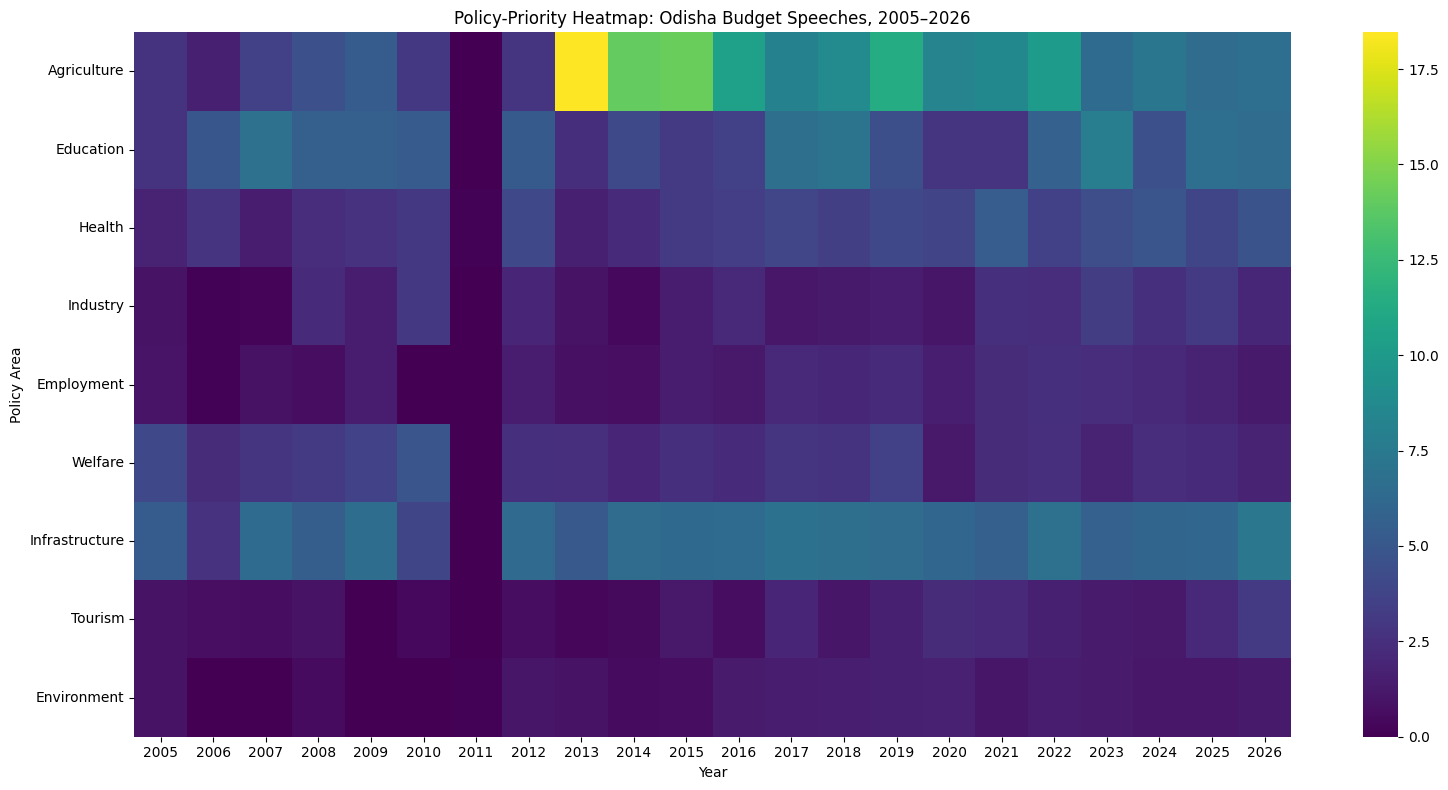

In [ ]:
# ============================================
# GRAPH 1: POLICY-PRIORITY HEATMAP
# ============================================

policy_cols = [
    "agriculture_per_1000",
    "education_per_1000",
    "health_per_1000",
    "industry_per_1000",
    "employment_per_1000",
    "welfare_per_1000",
    "infrastructure_per_1000",
    "tourism_per_1000",
    "environment_per_1000"
]

policy_labels = [
    "Agriculture",
    "Education",
    "Health",
    "Industry",
    "Employment",
    "Welfare",
    "Infrastructure",
    "Tourism",
    "Environment"
]

heatmap_data = odisha_df[
    ["year"] + policy_cols
].set_index("year").T

heatmap_data.index = policy_labels

plt.figure(figsize=(16, 8))

sns.heatmap(
    heatmap_data,
    cmap="viridis",
    annot=False
)

plt.title(
    "Policy-Priority Heatmap: Odisha Budget Speeches, 2005–2026"
)

plt.xlabel("Year")
plt.ylabel("Policy Area")

plt.tight_layout()

plt.savefig(
    "/content/Odisha_Graphs/1_Policy_Priority_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

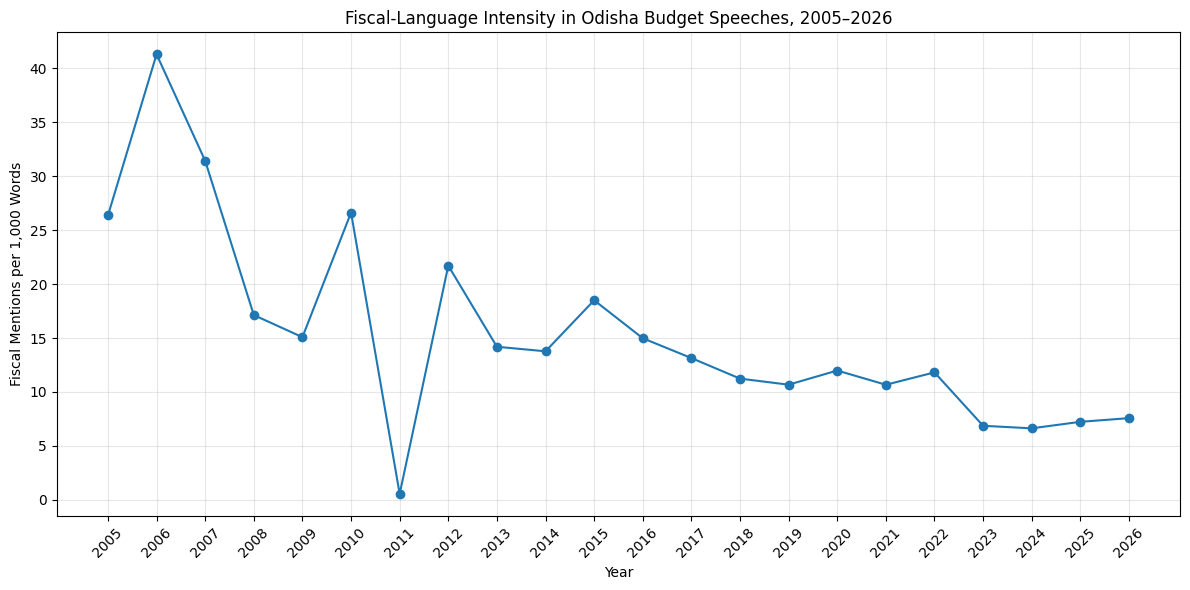

In [ ]:
# ============================================
# GRAPH 2: FISCAL-LANGUAGE INTENSITY
# ============================================

plt.figure(figsize=(12, 6))

plt.plot(
    odisha_df["year"],
    odisha_df["fiscal_intensity_per_1000"],
    marker="o"
)

plt.title(
    "Fiscal-Language Intensity in Odisha Budget Speeches, 2005–2026"
)

plt.xlabel("Year")
plt.ylabel("Fiscal Mentions per 1,000 Words")

plt.xticks(
    odisha_df["year"],
    rotation=45
)

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/Odisha_Graphs/2_Fiscal_Language_Intensity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

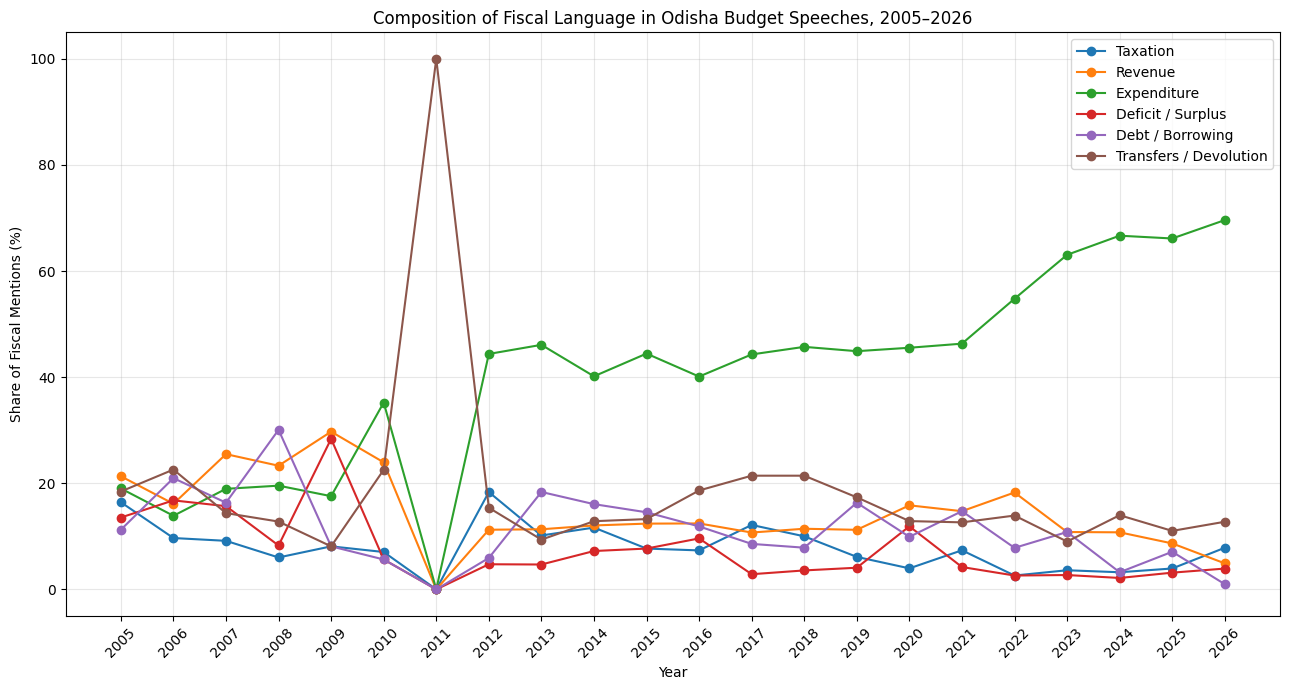

In [ ]:
# ============================================
# GRAPH 3: FISCAL-LANGUAGE COMPOSITION
# SAME AS MAHARASHTRA / GUJARAT
# ============================================

plt.figure(figsize=(13, 7))

plt.plot(
    odisha_df["year"],
    odisha_df["fiscal_taxation_share"] * 100,
    marker="o",
    label="Taxation"
)

plt.plot(
    odisha_df["year"],
    odisha_df["fiscal_revenue_share"] * 100,
    marker="o",
    label="Revenue"
)

plt.plot(
    odisha_df["year"],
    odisha_df["fiscal_expenditure_share"] * 100,
    marker="o",
    label="Expenditure"
)

plt.plot(
    odisha_df["year"],
    odisha_df["fiscal_deficit_surplus_share"] * 100,
    marker="o",
    label="Deficit / Surplus"
)

plt.plot(
    odisha_df["year"],
    odisha_df["fiscal_debt_borrowing_share"] * 100,
    marker="o",
    label="Debt / Borrowing"
)

plt.plot(
    odisha_df["year"],
    odisha_df["fiscal_transfers_devolution_share"] * 100,
    marker="o",
    label="Transfers / Devolution"
)

plt.title(
    "Composition of Fiscal Language in Odisha Budget Speeches, 2005–2026"
)

plt.xlabel("Year")
plt.ylabel("Share of Fiscal Mentions (%)")

plt.xticks(
    odisha_df["year"],
    rotation=45
)

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/content/Odisha_Graphs/03_fiscal_language_composition.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

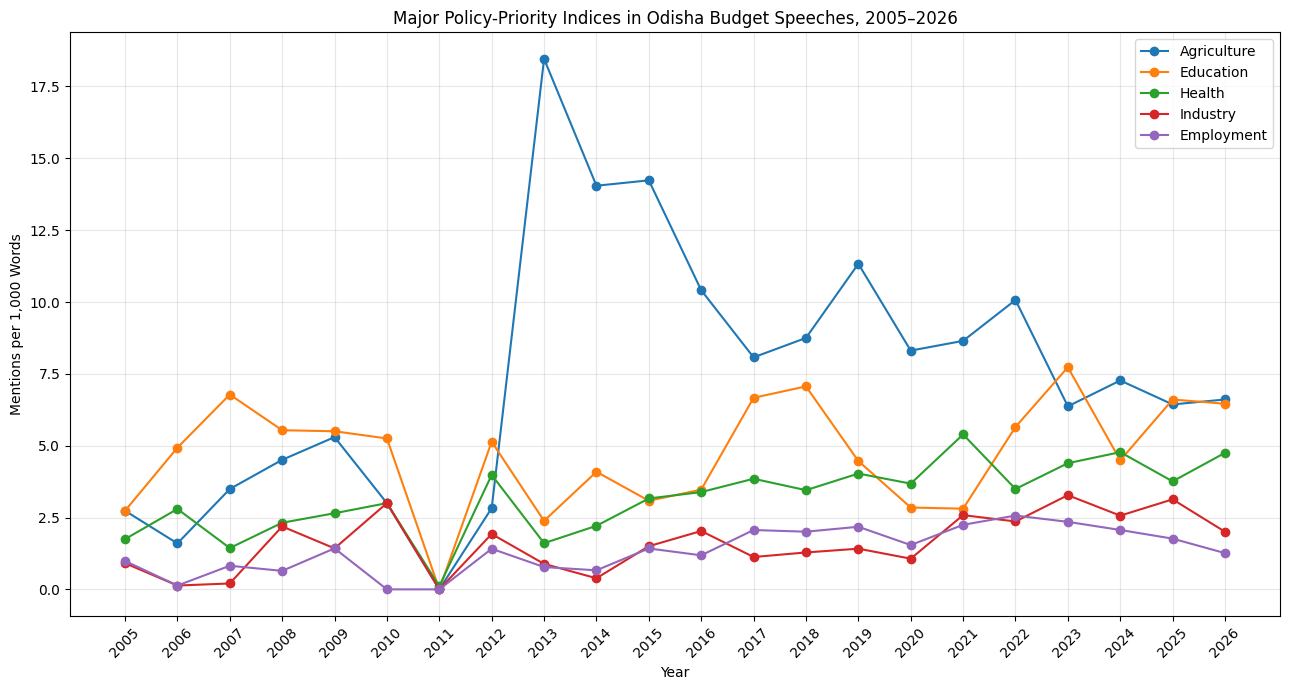

In [ ]:
# ============================================
# GRAPH 4: MAJOR POLICY-PRIORITY INDICES
# ============================================

major_policy = {
    "Agriculture": "agriculture_per_1000",
    "Education": "education_per_1000",
    "Health": "health_per_1000",
    "Industry": "industry_per_1000",
    "Employment": "employment_per_1000"
}

plt.figure(figsize=(13, 7))

for label, col in major_policy.items():

    plt.plot(
        odisha_df["year"],
        odisha_df[col],
        marker="o",
        label=label
    )

plt.title(
    "Major Policy-Priority Indices in Odisha Budget Speeches, 2005–2026"
)

plt.xlabel("Year")
plt.ylabel("Mentions per 1,000 Words")

plt.xticks(
    odisha_df["year"],
    rotation=45
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/content/Odisha_Graphs/4_Major_Policy_Priority_Indices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

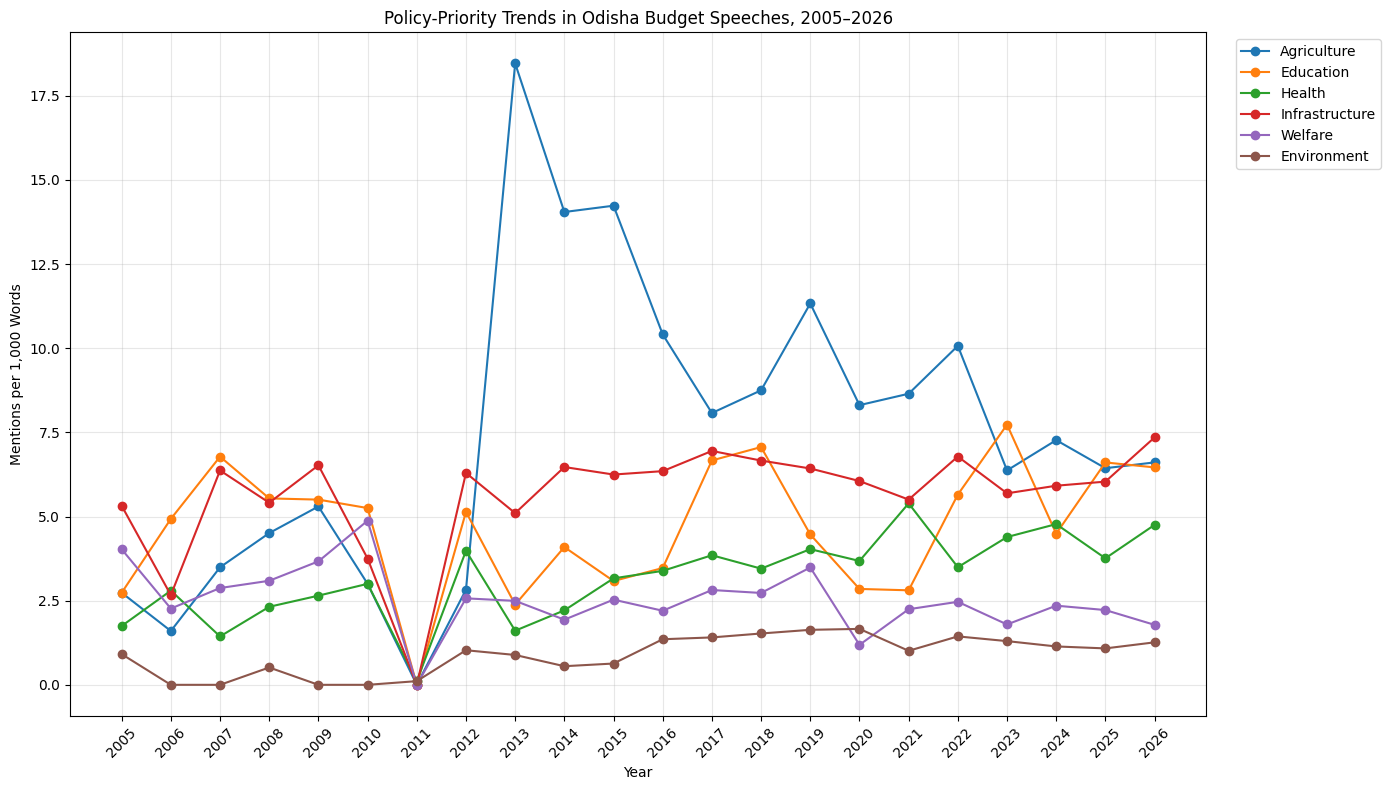

In [ ]:
# ============================================
# GRAPH 5: POLICY-PRIORITY TREND
# ============================================

policy_trend = {
    "Agriculture": "agriculture_per_1000",
    "Education": "education_per_1000",
    "Health": "health_per_1000",
    "Infrastructure": "infrastructure_per_1000",
    "Welfare": "welfare_per_1000",
    "Environment": "environment_per_1000"
}

plt.figure(figsize=(14, 8))

for label, col in policy_trend.items():

    plt.plot(
        odisha_df["year"],
        odisha_df[col],
        marker="o",
        label=label
    )

plt.title(
    "Policy-Priority Trends in Odisha Budget Speeches, 2005–2026"
)

plt.xlabel("Year")
plt.ylabel("Mentions per 1,000 Words")

plt.xticks(
    odisha_df["year"],
    rotation=45
)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/content/Odisha_Graphs/5_Policy_Priority_Trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()